# TP3 - Optimización de Modelos de Machine Learning

**Grupo:** 2

En este trabajo práctico se aborda un problema de **clasificación supervisada**: predecir si una reserva de infraestructura GPU será cancelada antes de su ejecución.

El rendimiento se mide con dos métricas: la balanced accuracy y el ROC-AUC. Su elección se justifica en la sección 6.1.

In [171]:
# IMPORTS

import pandas as pd
# pandas sirve para trabajar con datos en forma de tablas (DataFrames).

import numpy as np
import matplotlib.pyplot as plt

# Para que pandas muestre todas las columnas al imprimir un DataFrame
pd.set_option("display.max_columns", None)

## 1. Descripción del dataset

### 1.1 Contexto

El dataset contiene información sobre **reservas de GPUs** en una plataforma de cómputo.

Una **GPU** es un procesador especializado en realizar muchos cálculos en paralelo, muy utilizado para entrenar modelos de machine learning. Como son costosas, muchos usuarios no las compran sino que las alquilan por horas a plataformas que disponen de muchas GPUs conectadas entre sí.

Cada fila del dataset representa **una reserva**: un cliente solicita cierta cantidad y tipo de GPUs, para una fecha determinada y durante una cantidad de horas. Antes de esa fecha, el cliente puede cancelar la reserva. Predecir qué reservas se van a cancelar le permite a la plataforma reasignar esos recursos a otros clientes y evitar que queden sin uso.

La información disponible puede agruparse en:

- **Características temporales:** cuándo se programó la ejecución y con cuánta anticipación se hizo la reserva.
- **Recursos solicitados:** horas GPU, procesos, tipo de GPU y almacenamiento.
- **Historial del cliente:** si ya usó la plataforma y cuántas reservas canceló o completó antes.
- **Características económicas y contractuales:** costo por hora y tipo de compromiso.

La variable objetivo es `canceled_job`, que indica si la reserva fue cancelada (1) o no (0).

Predecir cancelaciones con anticipación permitiría a la plataforma planificar mejor la capacidad de cómputo, por ejemplo reasignando recursos o aplicando sobreventa controlada.

In [172]:
# CARGA DEL DATASET

# El CSV está en la carpeta data/, dentro del repo
df = pd.read_csv("data/gpu_resource_reservations.csv")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Filas: 47842
Columnas: 34


,canceled_job,hours_before_execution,execution_year,execution_month,execution_week,execution_day,peak_gpu_hours,offpeak_gpu_hours,num_primary_processes,num_auxiliary_processes,num_background_processes,service_tier,client_region,client_type,request_channel,returning_client,previous_job_cancellations,successful_previous_jobs,reserved_gpu_type,assigned_gpu_type,resource_modifications,reservation_commitment,orchestration_agent_id,organization_id,queue_wait_time,workload_profile,estimated_cost_per_hour,reserved_storage_units,special_resource_requests,execution_status,execution_status_date,total_processes,total_gpu_hours,high_value_client
0,0,6,2015,7,27,1,0,16,1,0.0,0,priority,PRT,managed_account,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,6.0,NaN,0,single_experiment,0.000,0,0,completed,2015-07-03,1.0,16,0
1,1,88,2015,7,27,1,0,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-07-01,2.0,32,0
2,1,92,2015,7,27,1,16,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,2,canceled,2015-06-23,2.0,48,0
3,1,79,2015,7,27,2,0,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-06-25,2.0,24,0
4,1,62,2015,7,27,2,16,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,8.0,NaN,0,single_experiment,3.825,0,1,no_show,2015-07-02,2.0,40,0


### 1.2 Diccionario de variables

A continuación se construye una tabla con todas las variables del dataset. Para cada una se muestra:

- **descripcion:** qué representa.
- **tipo_pandas:** cómo la interpreta pandas.
- **valores_unicos:** cantidad de valores distintos.
- **nulos:** cantidad de valores faltantes.
- **valores_posibles:** si tiene pocos valores, se listan todos; si es numérica con muchos valores, se muestra su rango; si es categórica con muchas categorías, se muestran las más frecuentes.

In [173]:
# DICCIONARIO DE VARIABLES

# Para que pandas muestre el texto completo de cada celda de la tabla
pd.set_option("display.max_colwidth", None)

# Descripción de cada variable (tomada de la consigna del TP)
descripciones = {
    "canceled_job": "Variable objetivo. Indica si la reserva fue cancelada o no llegó a ejecutarse.",
    "hours_before_execution": "Horas entre la creación de la reserva y el inicio programado de ejecución.",
    "execution_year": "Año del inicio programado de ejecución.",
    "execution_month": "Mes del inicio programado de ejecución.",
    "execution_week": "Semana del año del inicio programado de ejecución.",
    "execution_day": "Día del mes del inicio programado de ejecución.",
    "peak_gpu_hours": "Horas GPU reservadas en períodos de alta demanda.",
    "offpeak_gpu_hours": "Horas GPU reservadas en períodos de baja demanda.",
    "num_primary_processes": "Número de procesos principales asociados al workload.",
    "num_auxiliary_processes": "Número de procesos auxiliares asociados al workload.",
    "num_background_processes": "Número de procesos secundarios o de mantenimiento asociados al workload.",
    "service_tier": "Nivel de servicio contratado para la reserva.",
    "client_region": "País o región de procedencia del cliente.",
    "client_type": "Tipo de cliente que realiza la solicitud.",
    "request_channel": "Canal utilizado para realizar la reserva.",
    "returning_client": "Indica si el cliente ya había utilizado previamente la plataforma.",
    "previous_job_cancellations": "Cantidad de reservas canceladas previamente por el cliente.",
    "successful_previous_jobs": "Cantidad de reservas completadas exitosamente por el cliente.",
    "reserved_gpu_type": "Tipo de GPU solicitado originalmente.",
    "assigned_gpu_type": "Tipo de GPU finalmente asignado para la ejecución.",
    "resource_modifications": "Número de modificaciones realizadas sobre la reserva original.",
    "reservation_commitment": "Tipo de compromiso contractual asociado a la reserva.",
    "orchestration_agent_id": "Identificador del agente de orquestación asociado a la reserva.",
    "organization_id": "Identificador de la organización asociada a la reserva.",
    "queue_wait_time": "Tiempo de espera en cola antes de la asignación definitiva de recursos.",
    "workload_profile": "Perfil general o tipo de workload solicitado.",
    "estimated_cost_per_hour": "Costo estimado en USD por hora para el conjunto de recursos de la reserva.",
    "reserved_storage_units": "Cantidad de unidades de almacenamiento reservadas.",
    "special_resource_requests": "Número de solicitudes especiales asociadas a la reserva.",
    # Columnas que NO figuran en la consigna (descripción propia)
    "execution_status": "(No figura en la consigna) Estado final de la reserva.",
    "execution_status_date": "(No figura en la consigna) Fecha del último cambio de estado de la reserva.",
    "total_processes": "(No figura en la consigna) Total de procesos de la reserva.",
    "total_gpu_hours": "(No figura en la consigna) Total de horas GPU reservadas.",
    "high_value_client": "(No figura en la consigna) Indicador binario de cliente de alto valor.",
}


def valores_posibles(serie, max_categorias=12):
    """
    Devuelve un texto con los valores que toma una variable:
    - Si tiene pocos valores distintos, los lista todos.
    - Si es numérica con muchos valores, muestra el rango y la mediana.
    - Si es categórica con muchas categorías, muestra las 5 más frecuentes.
    """
    serie = serie.dropna()
    n_unicos = serie.nunique()

    # Numérica con muchos valores -> rango
    if pd.api.types.is_numeric_dtype(serie) and n_unicos > max_categorias:
        return f"Rango: {serie.min():g} a {serie.max():g} (mediana {serie.median():g})"

    # Pocos valores -> los listamos todos
    if n_unicos <= max_categorias:
        valores = sorted(serie.unique())
        return ", ".join(f"{v:g}" if isinstance(v, float) else str(v) for v in valores)

    # Categórica con muchas categorías -> las más frecuentes
    top = serie.value_counts().head(5).index.tolist()
    return f"{n_unicos} categorías. Más frecuentes: {', '.join(map(str, top))}"


diccionario = pd.DataFrame({
    "descripcion": pd.Series(descripciones),
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isna().sum(),
    "valores_posibles": [valores_posibles(df[col]) for col in df.columns],
})

diccionario

,descripcion,tipo_pandas,valores_unicos,nulos,valores_posibles
canceled_job,Variable objetivo. Indica si la reserva fue cancelada o no llegó a ejecutarse.,int64,2,0,"0, 1"
hours_before_execution,Horas entre la creación de la reserva y el inicio programado de ejecución.,int64,436,0,Rango: 0 a 629 (mediana 72)
execution_year,Año del inicio programado de ejecución.,int64,3,0,"2015, 2016, 2017"
execution_month,Mes del inicio programado de ejecución.,int64,12,0,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12"
execution_week,Semana del año del inicio programado de ejecución.,int64,53,0,Rango: 1 a 53 (mediana 27)
execution_day,Día del mes del inicio programado de ejecución.,int64,31,0,Rango: 1 a 31 (mediana 16)
peak_gpu_hours,Horas GPU reservadas en períodos de alta demanda.,int64,14,0,Rango: 0 a 128 (mediana 8)
offpeak_gpu_hours,Horas GPU reservadas en períodos de baja demanda.,int64,27,0,Rango: 0 a 328 (mediana 16)
num_primary_processes,Número de procesos principales asociados al workload.,int64,5,0,"0, 1, 2, 3, 4"
num_auxiliary_processes,Número de procesos auxiliares asociados al workload.,float64,4,1,"0, 1, 2, 3"


### 1.3 Descripción de las variables

A partir del diccionario anterior, se describen las variables agrupadas según el tipo de información que aportan.

#### Variable objetivo

- **`canceled_job`**: indica si la reserva fue cancelada o no llegó a ejecutarse. Toma los valores 0 (no cancelada) y 1 (cancelada).

#### Variables temporales

- **`hours_before_execution`**: horas entre la creación de la reserva y el inicio programado de ejecución. Va de 0 a 629, con mediana 72.
- **`execution_year`**: año del inicio programado. Toma los valores 2015, 2016 y 2017.
- **`execution_month`**: mes del inicio programado. Va de 1 a 12.
- **`execution_week`**: semana del año del inicio programado. Va de 1 a 53.
- **`execution_day`**: día del mes del inicio programado. Va de 1 a 31.

#### Recursos solicitados

- **`peak_gpu_hours`**: horas GPU reservadas en períodos de alta demanda. Va de 0 a 128, con mediana 8.
- **`offpeak_gpu_hours`**: horas GPU reservadas en períodos de baja demanda. Va de 0 a 328, con mediana 16.
- **`num_primary_processes`**: número de procesos principales. Toma valores de 0 a 4.
- **`num_auxiliary_processes`**: número de procesos auxiliares. Toma valores de 0 a 3 y tiene 1 valor faltante.
- **`num_background_processes`**: número de procesos secundarios o de mantenimiento. Toma los valores 0, 1, 2, 9 y 10.
- **`reserved_gpu_type`**: tipo de GPU solicitado originalmente. Tiene 8 categorías: GPU_T1, GPU_T2, GPU_T3, GPU_T4, GPU_T5, GPU_T6, GPU_T7 y GPU_T12.
- **`assigned_gpu_type`**: tipo de GPU finalmente asignado. Tiene 9 categorías: las mismas que la anterior más GPU_T10.
- **`reserved_storage_units`**: unidades de almacenamiento reservadas. Toma los valores 0, 1 y 2.
- **`special_resource_requests`**: número de solicitudes especiales. Toma valores de 0 a 5.
- **`queue_wait_time`**: tiempo de espera en cola antes de la asignación de recursos. Va de 0 a 391, con mediana 0.
- **`resource_modifications`**: número de modificaciones sobre la reserva original. Va de 0 a 20, con mediana 0.
- **`workload_profile`**: tipo de workload solicitado. Tiene 4 categorías: single_experiment, multi_run_experiment, long_term_contract y team_project.

#### Información del cliente

- **`client_type`**: tipo de cliente. Tiene 8 categorías: cloud_marketplace, managed_account, research_consortium, independent_client, enterprise_client, sponsored_project, high_priority_partner y unknown.
- **`client_region`**: país de procedencia del cliente. Tiene 149 categorías; las más frecuentes son PRT, FRA, DEU, GBR y ESP. Tiene 20 valores faltantes.
- **`request_channel`**: canal por el que se hizo la reserva. Tiene 5 categorías: broker_platform, api_direct, enterprise_portal, scheduler_gateway y unknown.
- **`returning_client`**: indica si el cliente ya había usado la plataforma. Toma los valores 0 y 1.
- **`previous_job_cancellations`**: reservas canceladas previamente por el cliente. Toma valores entre 0 y 21.
- **`successful_previous_jobs`**: reservas completadas exitosamente por el cliente. Va de **0 a 72**, con mediana 0.

#### Variables económicas y contractuales

- **`service_tier`**: nivel de servicio contratado. Tiene 4 categorías: basic, standard, priority y enterprise.
- **`reservation_commitment`**: tipo de compromiso contractual. Tiene 3 categorías: no_commitment, locked_allocation y flexible_commitment.
- **`estimated_cost_per_hour`**: costo estimado en USD por hora. Va de 0 a 270, con mediana 5.

#### Identificadores

- **`orchestration_agent_id`**: identificador del agente de orquestación. Tiene 194 valores distintos y 5.035 faltantes.
- **`organization_id`**: identificador de la organización. Tiene 175 valores distintos y 45.540 faltantes.

Aunque pandas los interpreta como números, son etiquetas: el agente 200 no es "mayor" que el agente 100. Por eso se tratarán como variables categóricas.

#### Variables que no figuran en la consigna

El dataset incluye cinco columnas que no aparecen en la descripción de la consigna:

- **`execution_status`**: estado final de la reserva. Tiene 3 categorías: completed, canceled y no_show.
- **`execution_status_date`**: fecha del último cambio de estado. Tiene 849 fechas distintas.
- **`total_processes`**: total de procesos. Toma valores entre 0 y 12.
- **`total_gpu_hours`**: total de horas GPU. Va de 0 a 456.
- **`high_value_client`**: indicador de cliente de alto valor. Toma los valores 0 y 1.

A continuación verificamos qué representan.

In [174]:
# VERIFICACIÓN DE LAS VARIABLES QUE NO FIGURAN EN LA CONSIGNA

# 1) ¿total_gpu_hours es la suma de las horas peak y offpeak?
suma_horas = df["peak_gpu_hours"] + df["offpeak_gpu_hours"]
print("total_gpu_hours = peak + offpeak en el",
      round((df["total_gpu_hours"] == suma_horas).mean() * 100, 3), "% de las filas")

# 2) ¿total_processes es la suma de los tres tipos de procesos?
suma_procesos = (df["num_primary_processes"]
                 + df["num_auxiliary_processes"]
                 + df["num_background_processes"])
print("total_processes = suma de procesos en el",
      round((df["total_processes"] == suma_procesos).mean() * 100, 3), "% de las filas")

# 3) Las horas GPU, ¿vienen en bloques de 8 horas?
multiplos_8 = (df["peak_gpu_hours"] % 8 == 0) & (df["offpeak_gpu_hours"] % 8 == 0)
print("peak y offpeak son múltiplos de 8 en el",
      round(multiplos_8.mean() * 100, 3), "% de las filas")

# 4) ¿high_value_client se relaciona con el costo por hora?
print("\nCosto por hora según high_value_client:")
print(df.groupby("high_value_client")["estimated_cost_per_hour"].describe().round(2))

# 5) ¿execution_status coincide con el target?
print("\nexecution_status vs canceled_job:")
print(pd.crosstab(df["execution_status"], df["canceled_job"]))

total_gpu_hours = peak + offpeak en el 100.0 % de las filas
total_processes = suma de procesos en el 99.998 % de las filas
peak y offpeak son múltiplos de 8 en el 100.0 % de las filas

Costo por hora según high_value_client:
                     count  mean   std  min   25%   50%   75%     max
high_value_client                                                    
0                  36525.0  4.55  1.24  0.0  3.75  4.55  5.49    6.62
1                  11317.0  7.56  3.24  0.0  6.84  7.50  8.50  270.00

execution_status vs canceled_job:
canceled_job          0      1
execution_status              
canceled              0  19416
completed         27887      0
no_show               0    539


#### Conclusiones sobre las variables que no figuran en la consigna

- **`total_gpu_hours`** es exactamente la suma de `peak_gpu_hours` y `offpeak_gpu_hours` (100% de las filas). Es una variable **redundante**.
- **`total_processes`** es la suma de los tres tipos de procesos (99,998% de las filas; la única excepción es la fila con el valor faltante). También es **redundante**.
- Las horas GPU vienen siempre en **bloques de 8 horas**, porque `peak_gpu_hours` y `offpeak_gpu_hours` son múltiplos de 8 en el 100% de las filas.
- **`high_value_client`**: los clientes marcados con 1 tienen un costo por hora mayor en promedio (7,56 vs. 4,55 USD), pero no hay un umbral exacto que los separe. Se conserva como variable.
- **`execution_status`** coincide exactamente con el target: "canceled" y "no_show" siempre corresponden a `canceled_job = 1`, y "completed" a `canceled_job = 0`. Es **data leakage**: el estado final de la reserva no se conoce al momento de predecir. Lo mismo ocurre con **`execution_status_date`**, que registra la fecha de la cancelación o de la finalización. **Ambas se eliminarán.**

## 2. Exploración inicial

En esta sección se analiza la estructura del dataset: el tipo de cada variable, los valores faltantes, el balance de la variable objetivo y las categorías poco frecuentes.

### 2.1 Clasificación de las variables

El tipo que asigna pandas no siempre coincide con el tipo conceptual de la variable. Por ejemplo, `orchestration_agent_id` aparece como número, pero es un **identificador**: el agente 200 no es "mayor" que el agente 100. Por eso clasificamos cada variable manualmente según su significado.

In [175]:
# CLASIFICACIÓN CONCEPTUAL DE CADA VARIABLE

tipos_variables = {
    "canceled_job": "Target (binaria)",
    "hours_before_execution": "Numérica discreta",
    "execution_year": "Temporal",
    "execution_month": "Temporal",
    "execution_week": "Temporal",
    "execution_day": "Temporal",
    "peak_gpu_hours": "Numérica discreta",
    "offpeak_gpu_hours": "Numérica discreta",
    "num_primary_processes": "Numérica discreta",
    "num_auxiliary_processes": "Numérica discreta",
    "num_background_processes": "Numérica discreta",
    "service_tier": "Categórica nominal",
    "client_region": "Categórica nominal (alta cardinalidad)",
    "client_type": "Categórica nominal",
    "request_channel": "Categórica nominal",
    "returning_client": "Binaria",
    "previous_job_cancellations": "Numérica discreta",
    "successful_previous_jobs": "Numérica discreta",
    "reserved_gpu_type": "Categórica nominal",
    "assigned_gpu_type": "Categórica nominal",
    "resource_modifications": "Numérica discreta",
    "reservation_commitment": "Categórica nominal",
    "orchestration_agent_id": "Identificador (categórica, alta cardinalidad)",
    "organization_id": "Identificador (categórica, alta cardinalidad)",
    "queue_wait_time": "Numérica discreta",
    "workload_profile": "Categórica nominal",
    "estimated_cost_per_hour": "Numérica continua",
    "reserved_storage_units": "Numérica discreta",
    "special_resource_requests": "Numérica discreta",
    "execution_status": "Leakage",
    "execution_status_date": "Leakage",
    "total_processes": "Redundante (suma de procesos)",
    "total_gpu_hours": "Redundante (suma de horas GPU)",
    "high_value_client": "Binaria",
}

# Agregamos la clasificación al diccionario armado en la sección 1
diccionario["tipo_variable"] = diccionario.index.map(tipos_variables)

# Cuántas variables hay de cada tipo
print(diccionario["tipo_variable"].value_counts())

# Tabla ordenada por tipo de variable
diccionario.sort_values("tipo_variable")[["tipo_variable", "tipo_pandas", "valores_unicos"]]

tipo_variable
Numérica discreta                                12
Categórica nominal                                7
Temporal                                          4
Binaria                                           2
Identificador (categórica, alta cardinalidad)     2
Leakage                                           2
Target (binaria)                                  1
Categórica nominal (alta cardinalidad)            1
Numérica continua                                 1
Redundante (suma de procesos)                     1
Redundante (suma de horas GPU)                    1
Name: count, dtype: int64


,tipo_variable,tipo_pandas,valores_unicos
high_value_client,Binaria,int64,2
returning_client,Binaria,int64,2
request_channel,Categórica nominal,str,5
client_type,Categórica nominal,str,8
service_tier,Categórica nominal,str,4
reservation_commitment,Categórica nominal,str,3
assigned_gpu_type,Categórica nominal,str,9
reserved_gpu_type,Categórica nominal,str,8
workload_profile,Categórica nominal,str,4
client_region,Categórica nominal (alta cardinalidad),str,149


El dataset tiene principalmente variables numéricas discretas (12), que son conteos como cantidad de procesos, horas o modificaciones, y variables categóricas nominales (7).

Además hay 4 variables temporales, 2 binarias, 2 identificadores y 1 numérica continua (`estimated_cost_per_hour`). Las 4 variables restantes (2 con leakage y 2 redundantes) se eliminarán más adelante.

### 2.2 Valores faltantes

                         nulos  porcentaje
organization_id          45540       95.19
orchestration_agent_id    5035       10.52
client_region               20        0.04
num_auxiliary_processes      1        0.00


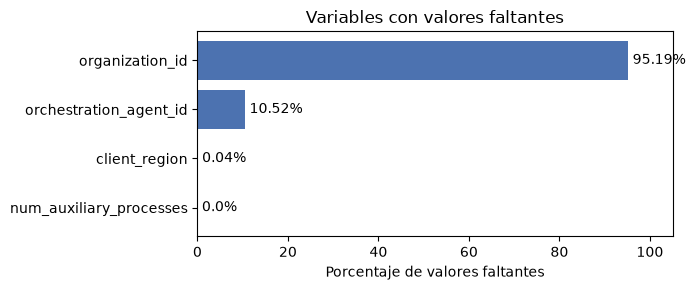

In [176]:
# VALORES FALTANTES

# Nos quedamos solo con las variables que tienen al menos un nulo
faltantes = diccionario.loc[diccionario["nulos"] > 0, ["nulos"]].copy()
faltantes["porcentaje"] = (faltantes["nulos"] / len(df) * 100).round(2)
faltantes = faltantes.sort_values("nulos", ascending=False)

print(faltantes)

# Gráfico de barras horizontales con el porcentaje de nulos
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(faltantes.index, faltantes["porcentaje"], color="#4C72B0")

# Escribimos el porcentaje al lado de cada barra
for i, v in enumerate(faltantes["porcentaje"]):
    ax.text(v + 1, i, f"{v}%", va="center")

ax.invert_yaxis()  # la variable con más nulos queda arriba
ax.set_xlim(0, 105)
ax.set_xlabel("Porcentaje de valores faltantes")
ax.set_title("Variables con valores faltantes")
plt.tight_layout()
plt.show()

Solo 4 variables tienen valores faltantes:

- **`organization_id`** (95,19%): la gran mayoría de las reservas no tiene organización asociada. El nulo probablemente significa "sin organización" y no un error de carga, así que en lugar de eliminar filas se tratará como una categoría propia.
- **`orchestration_agent_id`** (10,52%): ocurre lo mismo, el nulo probablemente significa "sin agente".
- **`client_region`** (20 filas) y **`num_auxiliary_processes`** (1 fila): son casos aislados. Se imputarán dentro del pipeline (con la moda o la mediana), ajustando la imputación solo con los datos de entrenamiento.

### 2.3 Variable objetivo

              cantidad  porcentaje
canceled_job                      
0                27887       58.29
1                19955       41.71


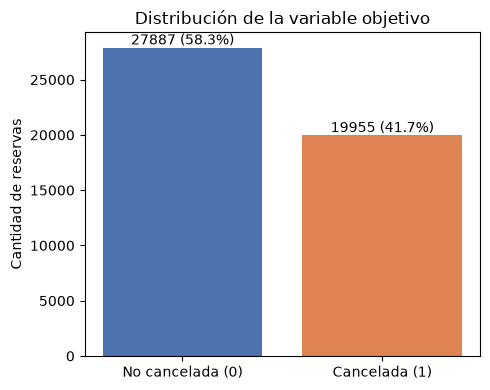

In [177]:
# DISTRIBUCIÓN DE LA VARIABLE OBJETIVO

conteo = df["canceled_job"].value_counts().sort_index()
porcentaje = df["canceled_job"].value_counts(normalize=True).sort_index() * 100

print(pd.DataFrame({"cantidad": conteo, "porcentaje": porcentaje.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No cancelada (0)", "Cancelada (1)"], conteo.values, color=["#4C72B0", "#DD8452"])

# Escribimos el valor arriba de cada barra
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v} ({porcentaje.values[i]:.1f}%)", ha="center", va="bottom")

ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Cantidad de reservas")
plt.tight_layout()
plt.show()

El 58,3% de las reservas no se canceló y el 41,7% sí. Hay un desbalance moderado.

Igualmente, este desbalance justifica dos decisiones:

- Usar **`stratify`** al separar train y test, para que ambos conjuntos mantengan la misma proporción de cancelaciones.
- Evaluar con **Balanced Accuracy**. Promedia el recall de cada clase, así que un modelo que favorezca a la clase mayoritaria no obtiene un buen puntaje. La elección de las métricas se desarrolla en la sección 6.1.

### 2.4 Categorías poco frecuentes

Las categorías con muy pocas observaciones son un problema para los modelos: no hay suficientes ejemplos para aprender su comportamiento. Identificamos las categorías que representan menos del 1% de las reservas.

In [178]:
# CATEGORÍAS POCO FRECUENTES (< 1% DE LAS RESERVAS)

umbral = 1  # porcentaje

cols_categoricas = [
    "service_tier",
    "client_type",
    "request_channel",
    "reserved_gpu_type",
    "assigned_gpu_type",
    "reservation_commitment",
    "workload_profile",
    "client_region",
]

filas = []

for col in cols_categoricas:

    # Porcentaje de reservas en cada categoría
    porc = df[col].value_counts(normalize=True) * 100

    # Categorías que no llegan al umbral
    raras = porc[porc < umbral]

    filas.append({
        "variable": col,
        "n_categorias": df[col].nunique(),
        "categorias_raras": len(raras),
        "reservas_en_categorias_raras": int(df[col].isin(raras.index).sum()),
        "ejemplos": ", ".join(raras.index[:5].astype(str)),
    })

pd.DataFrame(filas).set_index("variable")

,n_categorias,categorias_raras,reservas_en_categorias_raras,ejemplos
variable,,,,
service_tier,4,1,9,enterprise
client_type,8,3,464,"sponsored_project, high_priority_partner, unknown"
request_channel,5,2,110,"scheduler_gateway, unknown"
reserved_gpu_type,8,3,296,"GPU_T7, GPU_T3, GPU_T12"
assigned_gpu_type,9,4,670,"GPU_T7, GPU_T10, GPU_T3, GPU_T12"
reservation_commitment,3,1,12,flexible_commitment
workload_profile,4,1,177,team_project
client_region,149,135,5327,"ISR, SWE, POL, CN, NOR"


Todas las variables categóricas tienen al menos una categoría poco frecuente:

- **`client_region`** es el caso más extremo: 135 de sus 149 países representan menos del 1% de las reservas cada uno.
- En **`client_type`** y **`request_channel`** aparece la categoría `unknown` con una sola reserva.
- En **`service_tier`**, `enterprise` tiene solo 9 reservas. 
- En **`reservation_commitment`**, `flexible_commitment` tiene solo 12.

Para evitar que el modelo aprenda patrones a partir de muy pocos casos, estas categorías se agruparán en una categoría **"otros"**. La agrupación se definirá usando solo el conjunto de entrenamiento.

### 2.5 Conclusiones de la exploración inicial

| Hallazgo | Decisión |
|---|---|
| `execution_status` y `execution_status_date` contienen el resultado de la reserva | Eliminarlas (data leakage) |
| `total_gpu_hours` y `total_processes` son sumas de otras variables | Eliminarlas (redundantes) |
| `organization_id` y `orchestration_agent_id` son identificadores con muchos nulos | Tratarlas como categóricas, con el nulo como categoría "sin organización" / "sin agente" |
| `client_region` y `num_auxiliary_processes` tienen pocos nulos | Imputar dentro del pipeline |
| Desbalance moderado (58% / 42%) | Usar `stratify` y Balanced Accuracy |
| Categorías poco frecuentes | Agruparlas en "otros" |

## 3. Separación en train y test

Antes de analizar la relación de las variables con el target, separamos un conjunto de **test** que no se usará hasta la evaluación final. Antes del split hay dos pasos: eliminar las variables con leakage y decidir qué hacer con las filas duplicadas.

### 3.1 Eliminación de variables con leakage

Como se vio en la sección 1, `execution_status` y `execution_status_date` contienen el resultado de la reserva. Se eliminan antes del split para que no lleguen a ningún modelo.

In [179]:
# ELIMINACIÓN DE VARIABLES CON LEAKAGE

cols_leakage = ["execution_status", "execution_status_date"]

# Trabajamos sobre una copia para no modificar el df original
df_modelo = df.drop(columns=cols_leakage)

print("Columnas antes:", df.shape[1])
print("Columnas después:", df_modelo.shape[1])

Columnas antes: 34
Columnas después: 32


### 3.2 Filas duplicadas

Verificamos si hay reservas con exactamente los mismos valores en todas las variables (sin contar el target).

In [180]:
# FILAS DUPLICADAS

# Columnas que describen la reserva (todas menos el target)
cols_features = df_modelo.columns.drop("canceled_job")

# keep=False marca todas las copias, no solo las repetidas
duplicadas = df_modelo.duplicated(subset=cols_features, keep=False)
print(f"Filas con al menos una copia idéntica: {duplicadas.sum()} ({duplicadas.mean() * 100:.1f}%)")

# Asignamos un número de grupo a cada combinación distinta de valores.
# Las filas idénticas comparten el mismo número de grupo.
# dropna=False hace que los nulos también se consideren iguales entre sí.
grupos = df_modelo.groupby(list(cols_features), dropna=False).ngroup()

tamanio_grupos = grupos.value_counts()
print("Grupos con más de una fila:", (tamanio_grupos > 1).sum())
print("Tamaño del grupo más grande:", tamanio_grupos.max())

print("\nCantidad de grupos según su tamaño (primeros 10):")
print(tamanio_grupos[tamanio_grupos > 1].value_counts().sort_index().head(10))

Filas con al menos una copia idéntica: 19435 (40.6%)
Grupos con más de una fila: 3499
Tamaño del grupo más grande: 180

Cantidad de grupos según su tamaño (primeros 10):
count
2     2100
3      410
4      204
5      128
6       72
7       49
8       44
9       41
10      61
11      28
Name: count, dtype: int64


El 40,6% de las filas (19.435) tiene al menos una copia idéntica. Forman 3.499 grupos: la mayoría son pares, pero hay grupos de hasta 180 filas iguales.

El dataset no tiene un identificador de reserva, así que no se puede saber con certeza si son errores de carga o reservas distintas. Grupos tan grandes (misma fecha, mismo agente, mismo precio) sugieren reservas en bloque: un cliente que reserva muchas GPUs a la vez. Por eso no se eliminan.

El riesgo de conservarlas es que una copia quede en train y otra en test: el modelo se evaluaría sobre filas que ya vio y la métrica saldría optimista. Para evitarlo, el split se hace por grupos.

### 3.3 Split estratificado por grupos

Usamos `StratifiedGroupKFold` con 5 folds y tomamos uno como test (20%). Así se cumplen dos condiciones:

- **Estratificado:** train y test mantienen la proporción de cancelaciones.
- **Por grupos:** cada grupo de filas idénticas queda entero en train o en test.

La asignación de los grupos es aleatoria. La semilla (`random_state=42`) se fija una sola vez y no se cambia según los resultados, para no elegir un test "a medida". Los mismos grupos se usarán después en la validación cruzada.

In [181]:
# SPLIT TRAIN / TEST

from sklearn.model_selection import StratifiedGroupKFold

X = df_modelo.drop(columns="canceled_job")
y = df_modelo["canceled_job"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Tomamos el primer fold como test (1 de 5 = 20%)
idx_train, idx_test = next(sgkf.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

# Guardamos los grupos de train para usarlos en la validación cruzada
grupos_train = grupos.iloc[idx_train]

# Verificación 1: tamaño y proporción de cancelaciones en cada conjunto
print(pd.DataFrame({
    "filas": [len(y_train), len(y_test)],
    "porc_filas": [round(len(y_train) / len(y) * 100, 2), round(len(y_test) / len(y) * 100, 2)],
    "porc_canceladas": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train", "test"]))

# Verificación 2: ningún grupo de duplicados aparece en ambos conjuntos
compartidos = set(grupos.iloc[idx_train]) & set(grupos.iloc[idx_test])
print("\nGrupos presentes en train y en test a la vez:", len(compartidos))

       filas  porc_filas  porc_canceladas
train  38274        80.0            41.71
test    9568        20.0            41.70

Grupos presentes en train y en test a la vez: 0


El split quedó con 38.274 filas en train (80%) y 9.568 en test (20%), ambos con 41,7% de cancelaciones y ningún grupo de duplicados aparece en los dos conjuntos.

A partir de acá, el test no se vuelve a mirar hasta la evaluación final. Todo el análisis y las decisiones siguientes se hacen solo con train.

## 4. Análisis exploratorio

Con el test ya separado, se analiza la relación entre cada variable y la cancelación. Todo este análisis usa **únicamente el conjunto de entrenamiento**: mirar el test en esta etapa equivaldría a tomar decisiones a partir de datos que deben quedar reservados para la evaluación final.

### 4.1 Variables numéricas

El análisis de las variables numéricas tiene dos partes:

1. Correlación entre variables: busca variables que repiten la misma información (redundancia).
2. Relación con el target: busca qué variables ayudan a predecir la cancelación.

En ambas se usan dos coeficientes de correlación:

- Pearson mide relaciones lineales y es sensible a los valores extremos.
- Spearman trabaja con el orden de los valores (rangos), así que detecta cualquier relación monótona y es robusto a outliers y a distribuciones asimétricas, como las de `hours_before_execution` o `queue_wait_time`.

Los identificadores (`orchestration_agent_id` y `organization_id`) quedan fuera de este análisis. Como se explicó en la sección 1, son etiquetas y no números: el agente 200 no es "mayor" que el agente 100, así que calcular su correlación no tiene sentido. En el preprocesamiento se tratan como categóricas.

#### Correlación entre variables

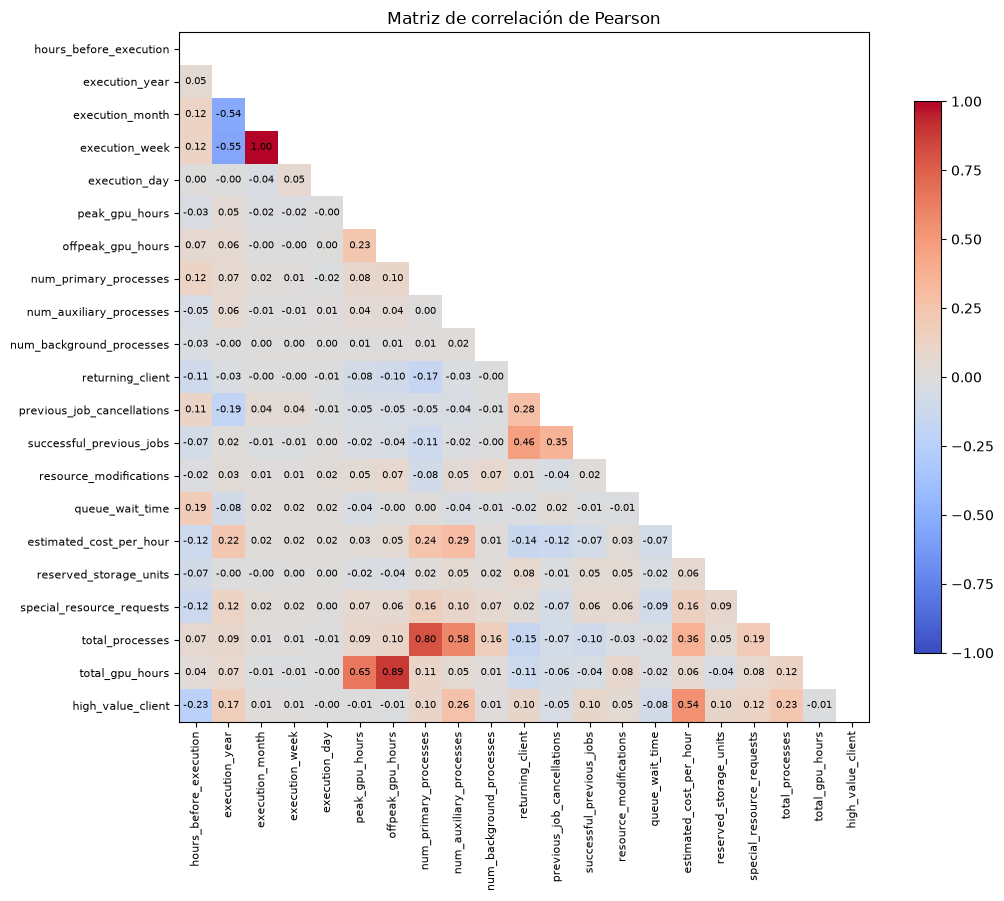

pearson  spearman
variable_1                 variable_2                                 
execution_month            execution_week               1.00      1.00
num_primary_processes      total_processes              0.80      0.90
offpeak_gpu_hours          total_gpu_hours              0.89      0.80
returning_client           successful_previous_jobs     0.46      0.79
estimated_cost_per_hour    high_value_client            0.54      0.58
peak_gpu_hours             total_gpu_hours              0.65      0.56
execution_year             execution_week              -0.55     -0.55
                           execution_month             -0.54     -0.54
num_auxiliary_processes    total_processes              0.58      0.46
estimated_cost_per_hour    total_processes              0.36      0.33
previous_job_cancellations successful_previous_jobs     0.35      0.13

Máximo de semanas distintas para una misma fecha: 1


In [182]:
# CORRELACIÓN ENTRE VARIABLES NUMÉRICAS

# Juntamos features y target en un solo DataFrame, solo para el análisis
train = X_train.copy()
train["canceled_job"] = y_train

# Los identificadores son etiquetas, no números: quedan fuera del análisis de correlación
cols_identificadores = ["orchestration_agent_id", "organization_id"]

# Numéricas: todas las que no son categóricas de texto ni identificadores
cols_numericas_eda = [c for c in X_train.columns
                      if c not in cols_categoricas and c not in cols_identificadores]

corr_pearson = train[cols_numericas_eda].corr(method="pearson")
corr_spearman = train[cols_numericas_eda].corr(method="spearman")

# 1) MATRIZ DE CORRELACIÓN DE PEARSON
# Mostramos solo el triángulo inferior, porque la matriz es simétrica
mascara = np.triu(np.ones(corr_pearson.shape, dtype=bool))
valores = corr_pearson.mask(mascara)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(valores, cmap="coolwarm", vmin=-1, vmax=1)

# Escribimos el valor en cada celda
for i in range(len(corr_pearson)):
    for j in range(i):
        ax.text(j, i, f"{corr_pearson.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)

ax.set_xticks(range(len(corr_pearson)))
ax.set_xticklabels(corr_pearson.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr_pearson)))
ax.set_yticklabels(corr_pearson.columns, fontsize=8)
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

# 2) PARES MÁS CORRELACIONADOS: PEARSON vs SPEARMAN
# Nos quedamos con los pares con |r| >= 0,3 en alguno de los dos coeficientes
triangulo = np.triu(np.ones(corr_pearson.shape, dtype=bool), k=1)
pares = pd.DataFrame({
    "pearson": corr_pearson.where(triangulo).stack(),
    "spearman": corr_spearman.where(triangulo).stack(),
})
pares = pares[(pares["pearson"].abs() >= 0.3) | (pares["spearman"].abs() >= 0.3)]
pares = pares.reindex(pares["spearman"].abs().sort_values(ascending=False).index)
pares.index.names = ["variable_1", "variable_2"]

display(pares.round(2))

# 3) ¿execution_week queda determinada por la fecha (año, mes y día)?
semanas_por_fecha = train.groupby(["execution_year", "execution_month", "execution_day"])["execution_week"].nunique()
print("Máximo de semanas distintas para una misma fecha:", semanas_por_fecha.max())

Los pares con correlación alta o moderada son:

- `execution_month` y `execution_week` (1,00 en ambos coeficientes): son prácticamente la misma variable. Además, la semana queda completamente determinada por la fecha: cada combinación de año, mes y día tiene una única semana.
- `total_gpu_hours` y `total_processes` con sus componentes (entre 0,46 y 0,90): confirma lo verificado en la sección 1, son sumas de otras columnas.
- `execution_year` con `execution_month` y `execution_week` (-0,55): no es una relación real, sino un efecto del período que cubre el dataset. 2015 solo tiene reservas de julio a diciembre y 2017 de enero a agosto, por lo que el año "predice" en parte el mes.
- `returning_client` y `successful_previous_jobs` (0,46 Pearson, 0,79 Spearman): quien vuelve a la plataforma tiene reservas previas. Spearman es mucho más alto porque la relación es monótona pero no lineal (casi todos los valores de `successful_previous_jobs` son 0). Aportan información distinta: una indica si el cliente volvió y la otra cuántas reservas completó.
- `estimated_cost_per_hour` y `high_value_client` (0,54 y 0,58): coincide con lo visto en la sección 1. La relación es moderada y no hay un umbral que las separe, así que no son redundantes.

#### Relación con el target

Para cada variable se compara su promedio en cada clase y se calculan tres medidas: Pearson, Spearman e información mutua. La información mutua mide cuánto se reduce la incertidumbre sobre el target al conocer la variable. A diferencia de las correlaciones, detecta cualquier tipo de relación, incluso las que no son monótonas, y vale 0 cuando la variable y el target son independientes.

In [183]:
# RELACIÓN DE LAS VARIABLES NUMÉRICAS CON EL TARGET

from sklearn.feature_selection import mutual_info_classif

# Valor promedio de cada variable en cada clase
comparacion = train.groupby("canceled_job")[cols_numericas_eda].mean().T
comparacion.columns = ["no_cancelada", "cancelada"]
comparacion["diferencia"] = comparacion["cancelada"] - comparacion["no_cancelada"]

# Correlación de cada variable con el target
comparacion["pearson"] = [train[c].corr(train["canceled_job"], method="pearson")
                          for c in cols_numericas_eda]
comparacion["spearman"] = [train[c].corr(train["canceled_job"], method="spearman")
                           for c in cols_numericas_eda]

# Información mutua: no admite nulos, así que completamos el único faltante con la mediana
X_mi = train[cols_numericas_eda].fillna(train[cols_numericas_eda].median())
comparacion["info_mutua"] = mutual_info_classif(X_mi, train["canceled_job"], random_state=42)

# Ordenamos por información mutua: arriba las más informativas
comparacion.sort_values("info_mutua", ascending=False).round(3)

,no_cancelada,cancelada,diferencia,pearson,spearman,info_mutua
hours_before_execution,81.148,143.399,62.251,0.282,0.305,0.106
estimated_cost_per_hour,5.282,5.217,-0.065,-0.013,-0.038,0.096
special_resource_requests,0.738,0.279,-0.459,-0.290,-0.323,0.057
previous_job_cancellations,0.020,0.165,0.145,0.169,0.279,0.050
queue_wait_time,2.210,4.776,2.566,0.058,0.120,0.028
resource_modifications,0.262,0.083,-0.179,-0.148,-0.190,0.019
reserved_storage_units,0.041,0.000,-0.041,-0.132,-0.132,0.016
total_gpu_hours,23.294,24.499,1.205,0.039,0.028,0.014
total_processes,1.928,1.946,0.018,0.014,0.019,0.008
successful_previous_jobs,0.221,0.018,-0.203,-0.057,-0.098,0.007


Las variables numéricas más relacionadas con la cancelación son:

- `hours_before_execution` (Spearman 0,31; información mutua 0,106, la más alta): las canceladas se reservaron con 143 horas de anticipación en promedio, frente a 81 las no canceladas. Reservar con mucha antelación da más tiempo y más motivos para cancelar.
- `special_resource_requests` (Spearman -0,32): las reservas que no se cancelan piden en promedio 0,74 solicitudes especiales, contra 0,28 las que sí se cancelan. Pedir extras parece indicar un cliente comprometido con la reserva.
- `previous_job_cancellations` (Spearman 0,28, frente a 0,17 de Pearson): quien ya canceló antes vuelve a cancelar. La diferencia entre coeficientes se debe a que casi todos los valores son 0 y unos pocos son muy altos.
- `resource_modifications` (-0,19) y `reserved_storage_units` (-0,13): modificar la reserva o reservar almacenamiento indican compromiso. En train, ninguna reserva cancelada tiene almacenamiento reservado.

El caso de `estimated_cost_per_hour` muestra por qué no alcanza con mirar la correlación: su Pearson es prácticamente 0 (-0,01) y el promedio casi no cambia entre clases, pero es la segunda variable con mayor información mutua (0,096). La relación con la cancelación existe, pero no es lineal ni monótona.

En el otro extremo, las variables temporales (`execution_year`, `execution_month`, `execution_week`, `execution_day`) y las de procesos tienen correlaciones e información mutua prácticamente nulas. Esto no alcanza para descartarlas: estas medidas analizan cada variable por separado, y un modelo de árboles puede aprovecharlas combinadas con otras.

#### Variables a eliminar

A partir de los dos análisis anteriores, se eliminan las siguientes variables:

| Variable | Motivo |
|---|---|
| `total_gpu_hours` | Es la suma exacta de `peak_gpu_hours` y `offpeak_gpu_hours` (sección 1). No agrega información y genera colinealidad en modelos lineales. |
| `total_processes` | Es la suma exacta de los tres tipos de procesos (sección 1). Mismo motivo. |
| `execution_week` | Tiene correlación 1,00 con `execution_month` y queda determinada por año, mes y día, así que no aporta nada que no esté en esas tres variables. Se elimina la semana y no el mes porque el mes no queda determinado por la semana: hay semanas que caen en dos meses distintos. |

El resto de las variables se conserva. Los casos que podrían generar dudas son tres:

- **`estimated_cost_per_hour`**: su correlación con el target es casi nula (Pearson −0,01), pero es la segunda variable con mayor información mutua (0,096). Las dos medidas no se contradicen. La correlación solo detecta relaciones en las que, al aumentar el costo, la cancelación aumenta o disminuye siempre en el mismo sentido. La información mutua detecta cualquier tipo de relación, por ejemplo que ciertos rangos de precio cancelen mucho y otros poco. Eliminarla por su correlación sería descartar una variable que sí aporta información.
- **Variables con poca relación individual con el target** (`execution_day`, las de procesos, `returning_client`, etc.): todas las medidas usadas analizan cada variable por separado. Una variable puede no servir sola y ser útil combinada con otras. Por ejemplo, el día del mes junto con el mes identifica fechas puntuales, como feriados. Los modelos de árboles detectan este tipo de combinaciones, así que la decisión de eliminarlas se toma más adelante con el modelo, comparando el rendimiento con y sin ellas.
- **`execution_year`**: el train incluye los tres años del dataset (2015, 2016 y 2017), así que el modelo los conoce todos. El riesgo aparecería si los datos de evaluación correspondieran a un año nuevo: el modelo no tendría ejemplos de ese año y podría aprender patrones que no se repiten. Como el dataset cubre un período continuo sin huecos, es más probable que el conjunto de evaluación pertenezca al mismo período. Igual, su impacto se medirá más adelante entrenando con y sin ella.

In [184]:
# ELIMINACIÓN DE VARIABLES REDUNDANTES

cols_eliminar = ["total_gpu_hours", "total_processes", "execution_week"]

# Se eliminan de train y de test. Quitar columnas no usa información de los datos,
# así que hacerlo en ambos conjuntos no genera leakage.
# errors="ignore" permite volver a correr la celda sin que falle.
X_train = X_train.drop(columns=cols_eliminar, errors="ignore")
X_test = X_test.drop(columns=cols_eliminar, errors="ignore")
train = train.drop(columns=cols_eliminar, errors="ignore")

print("Columnas de X_train:", X_train.shape[1])
print("Columnas de X_test:", X_test.shape[1])

Columnas de X_train: 28
Columnas de X_test: 28


### 4.2 Variables categóricas

El análisis de las variables categóricas sigue la misma lógica que el de las numéricas, pero con otras herramientas, porque Pearson y Spearman solo se pueden calcular sobre números. Tiene tres partes:

1. Tasa de cancelación por categoría, para las variables categóricas y para los identificadores.
2. Asociación entre variables categóricas: busca variables que repiten la misma información.
3. Asociación con el target: mide qué variables categóricas se relacionan más con la cancelación.

#### Tasa de cancelación por categoría

Para cada categoría se calcula la proporción de reservas canceladas. Si las tasas son muy distintas entre categorías, la variable ayuda a predecir la cancelación. Si todas quedan cerca del promedio del train (41,7%), aporta poco.

Este análisis complementa al test de chi-cuadrado de más abajo: la V de Cramér resume en un solo número cuánto difieren las tasas y sirve para comparar variables entre sí, pero no indica qué categorías cancelan más. Eso es lo que muestra esta tabla.

Se muestran solo las categorías con al menos 30 reservas, porque con menos casos la proporción puede salir alta o baja por azar.

In [185]:
# TASA DE CANCELACIÓN POR CATEGORÍA

# Con menos de 30 reservas la proporción no es confiable
minimo_reservas = 30

for col in cols_categoricas:

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa_cancelacion=("canceled_job", "mean"),
    )

    # Dejamos afuera las categorías con muy pocos casos
    tabla = tabla[tabla["reservas"] >= minimo_reservas]

    # client_region tiene 149 categorías: mostramos solo las más frecuentes
    if col == "client_region":
        tabla = tabla.sort_values("reservas", ascending=False).head(8)
    else:
        tabla = tabla.sort_values("tasa_cancelacion", ascending=False)

    print(f"\n=== {col} ===")
    print(tabla.round(3))


=== service_tier ===
              reservas  tasa_cancelacion
service_tier                            
standard         30049             0.429
basic             5049             0.377
priority          3168             0.369

=== client_type ===
                       reservas  tasa_cancelacion
client_type                                      
research_consortium        6638             0.668
managed_account            8361             0.440
cloud_marketplace         18521             0.376
enterprise_client          1460             0.234
high_priority_partner       129             0.209
independent_client         2910             0.167
sponsored_project           254             0.118

=== request_channel ===
                   reservas  tasa_cancelacion
request_channel                              
broker_platform       33269             0.451
enterprise_portal      1659             0.220
api_direct             3260             0.180
scheduler_gateway        85             0.094



Hay variables categóricas que separan muy bien las dos clases:

- **`reservation_commitment`**: las reservas con `locked_allocation` se cancelan en el 99,8% de los casos (6.274 reservas), frente al 30,3% de `no_commitment`. Es la variable más predictiva del dataset. Es información contractual conocida al momento de reservar, así que no constituye leakage, pero una variable que determina el resultado casi por completo merece mencionarse explícitamente.
- **`client_type`**: va del 66,8% en `research_consortium` al 11,8% en `sponsored_project`.
- **`client_region`**: Portugal (PRT) concentra el 39,2% del train y cancela el 64,9%, mientras que los demás países frecuentes cancelan entre el 17,5% (DEU) y el 38,3% (ITA).
- **`request_channel`**: `broker_platform` cancela el 45,1% y `api_direct` el 18,0%. Reservar a través de un intermediario se asocia a mucha más cancelación que hacerlo directo por API.
- **`workload_profile`**: `single_experiment` cancela el 46,1% y `multi_run_experiment` el 26,6%.

#### Identificadores

Los identificadores quedaron fuera del análisis de correlación porque son etiquetas. Acá se analizan igual que las categóricas: tasa de cancelación por valor, mostrando los nulos como "sin agente" y "sin organización". Se consideran solo los valores con al menos 100 reservas.

In [186]:
# TASA DE CANCELACIÓN POR IDENTIFICADOR

minimo_reservas_id = 100

identificadores = {
    "orchestration_agent_id": "sin agente",
    "organization_id": "sin organización",
}

for col, etiqueta_nulo in identificadores.items():

    # Pasamos el id a texto y reemplazamos el nulo por su etiqueta
    ids = train[col].fillna(-1).astype(int).astype(str).replace("-1", etiqueta_nulo)

    tabla = train.groupby(ids)["canceled_job"].agg(
        reservas="size",
        tasa_cancelacion="mean",
    )
    tabla = tabla[tabla["reservas"] >= minimo_reservas_id]

    print(f"\n=== {col} ({len(tabla)} valores con al menos {minimo_reservas_id} reservas) ===")
    print(tabla.sort_values("reservas", ascending=False).head(8).round(3))
    print(f"Rango de la tasa de cancelación: {tabla['tasa_cancelacion'].min():.1%} "
          f"a {tabla['tasa_cancelacion'].max():.1%}")


=== orchestration_agent_id (35 valores con al menos 100 reservas) ===
                        reservas  tasa_cancelacion
orchestration_agent_id                            
9                          15265             0.419
sin agente                  4030             0.320
1                           3153             0.712
14                          1722             0.172
7                           1705             0.130
6                           1316             0.372
37                           824             0.623
28                           805             0.065
Rango de la tasa de cancelación: 6.5% a 100.0%

=== organization_id (5 valores con al menos 100 reservas) ===
                  reservas  tasa_cancelacion
organization_id                             
sin organización     36415             0.427
40                     446             0.078
67                     146             0.712
45                     117             0.111
153                    115             

Aunque no se pueden analizar con Pearson ni Spearman, los identificadores están entre las variables más informativas del dataset:

- **`orchestration_agent_id`**: entre los 35 agentes con al menos 100 reservas, la tasa de cancelación va del 6,5% al 100%. El agente 1 cancela el 71,2% y el agente 28 el 6,5%. El agente 9 concentra el 39,9% del train.
- **`organization_id`**: el 95% de las reservas no tiene organización y cancela el 42,7%, prácticamente igual que el promedio. Entre las pocas organizaciones frecuentes también hay diferencias grandes: la 40 cancela el 7,8% y la 67 el 71,2%.

Esto confirma la decisión de la sección 2.5 de tratarlos como categóricas.

#### Asociación entre variables categóricas

Para medir la relación entre dos variables categóricas se usa el test de chi-cuadrado de independencia. Compara la tabla de frecuencias observada (cuántas reservas hay en cada combinación de categorías) con la que se esperaría si las variables fueran independientes. Cuanto más se alejan, mayor es el estadístico chi-cuadrado.

El chi-cuadrado crece con la cantidad de filas y de categorías, así que no sirve para comparar variables entre sí. Para eso se usa la V de Cramér, que lo lleva a una escala de 0 (independientes) a 1 (una variable determina a la otra) y se lee como una correlación. Se aplica la corrección de Bergsma, porque sin ella la V sale inflada en variables con muchas categorías, como `client_region` o los identificadores.

A diferencia de Pearson y Spearman, la V de Cramér sí se puede calcular para los identificadores, porque los trata como etiquetas. Por eso acá se incluyen junto con las demás categóricas. Los nulos se cuentan como una categoría más ("sin dato"), igual que en el preprocesamiento.

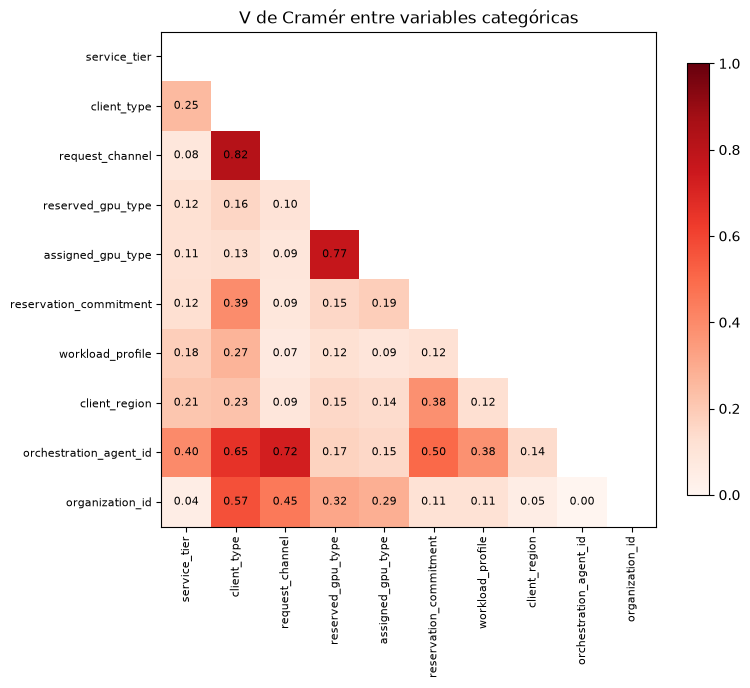

v_cramer
variable_1             variable_2                      
client_type            request_channel             0.82
reserved_gpu_type      assigned_gpu_type           0.77
request_channel        orchestration_agent_id      0.72
client_type            orchestration_agent_id      0.65
                       organization_id             0.57
reservation_commitment orchestration_agent_id      0.50
request_channel        organization_id             0.45
service_tier           orchestration_agent_id      0.40
client_type            reservation_commitment      0.39
reservation_commitment client_region               0.38
workload_profile       orchestration_agent_id      0.38
reserved_gpu_type      organization_id             0.32

Conociendo client_type se acierta request_channel en el 98.3% de las reservas
Conociendo request_channel se acierta client_type en el 59.2% de las reservas
Conociendo reserved_gpu_type se acierta assigned_gpu_type en el 90.9% de las reservas


In [187]:
# ASOCIACIÓN ENTRE VARIABLES CATEGÓRICAS (V DE CRAMÉR)

from scipy.stats import chi2_contingency


def v_cramer(a, b):
    """
    V de Cramér entre dos variables categóricas, con la corrección de Bergsma.
    Va de 0 (independientes) a 1 (una determina a la otra).
    La corrección reduce el sesgo hacia arriba en variables con muchas categorías.
    """
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    r, k = tabla.shape

    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)

    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))


# Categóricas de texto + identificadores
cols_cat_eda = list(cols_categoricas) + cols_identificadores

# Los nulos se tratan como una categoría más, igual que en el preprocesamiento
train_cat = train[cols_cat_eda].astype("string").fillna("sin dato")

# 1) MATRIZ DE V DE CRAMÉR
matriz_v = pd.DataFrame(
    [[v_cramer(train_cat[a], train_cat[b]) for b in cols_cat_eda] for a in cols_cat_eda],
    index=cols_cat_eda, columns=cols_cat_eda,
)

# Mostramos solo el triángulo inferior, porque la matriz es simétrica
mascara = np.triu(np.ones(matriz_v.shape, dtype=bool))
valores = matriz_v.mask(mascara)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(valores, cmap="Reds", vmin=0, vmax=1)

# Escribimos el valor en cada celda
for i in range(len(matriz_v)):
    for j in range(i):
        ax.text(j, i, f"{matriz_v.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

ax.set_xticks(range(len(matriz_v)))
ax.set_xticklabels(matriz_v.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(matriz_v)))
ax.set_yticklabels(matriz_v.columns, fontsize=8)
ax.set_title("V de Cramér entre variables categóricas")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

# 2) PARES MÁS ASOCIADOS (V >= 0,3)
triangulo = np.triu(np.ones(matriz_v.shape, dtype=bool), k=1)
pares_cat = matriz_v.where(triangulo).stack().rename("v_cramer").to_frame()
pares_cat = pares_cat[pares_cat["v_cramer"] >= 0.3].sort_values("v_cramer", ascending=False)
pares_cat.index.names = ["variable_1", "variable_2"]

display(pares_cat.round(2))


# 3) ¿UNA VARIABLE DETERMINA A LA OTRA?
# Porcentaje de reservas en las que, conociendo la primera variable,
# se acierta la segunda eligiendo su categoría más frecuente
def porcentaje_determinado(a, b):
    mas_frecuente = train_cat.groupby(a)[b].transform(lambda s: s.mode().iloc[0])
    return (mas_frecuente == train_cat[b]).mean() * 100


for a, b in [("client_type", "request_channel"), ("request_channel", "client_type"),
             ("reserved_gpu_type", "assigned_gpu_type")]:
    print(f"Conociendo {a} se acierta {b} en el {porcentaje_determinado(a, b):.1f}% de las reservas")

Los pares más asociados son:

- `client_type` y `request_channel` (0,82): cada tipo de cliente reserva casi siempre por el mismo canal. Conociendo el tipo de cliente se acierta el canal en el 98,3% de las reservas, pero al revés solo en el 59,2%. Dentro de `broker_platform` conviven `cloud_marketplace`, `managed_account` y `research_consortium`, que cancelan de forma muy distinta (37,6%, 44,0% y 66,8%). Es decir, `client_type` contiene casi toda la información de `request_channel` y además agrega la suya.
- `reserved_gpu_type` y `assigned_gpu_type` (0,77): en el 90,9% de las reservas la GPU asignada es la más común para el tipo reservado. En qué casos difieren se analiza en la sección 4.5.
- `orchestration_agent_id` con `request_channel` (0,72), `client_type` (0,65) y `reservation_commitment` (0,50): cada agente trabaja con ciertos tipos de cliente, canales y contratos. Esto explica en parte por qué el agente es tan informativo: resume información de varias variables.
- `organization_id` con `client_type` (0,57) y `request_channel` (0,45): las reservas con organización corresponden a ciertos tipos de cliente.

El resto de los pares tiene asociaciones moderadas o bajas (V menor a 0,4).

#### Asociación con el target

Se aplica el mismo test entre cada variable categórica y `canceled_job`. Además del estadístico y su p-valor se muestra la V de Cramér, que es la medida que permite comparar las variables entre sí.

In [188]:
# ASOCIACIÓN DE LAS VARIABLES CATEGÓRICAS CON EL TARGET

filas_chi2 = []

for col in cols_cat_eda:

    tabla = pd.crosstab(train_cat[col], train["canceled_job"])
    chi2, p_valor, _, _ = chi2_contingency(tabla, correction=False)

    filas_chi2.append({
        "variable": col,
        "categorias": train_cat[col].nunique(),
        "chi2": chi2,
        "p_valor": p_valor,
        "v_cramer": v_cramer(train_cat[col], train["canceled_job"]),
    })

asociacion_target = pd.DataFrame(filas_chi2).set_index("variable")

# Ordenamos por V de Cramér: arriba las más asociadas con la cancelación
asociacion_target.sort_values("v_cramer", ascending=False).round(3)

,categorias,chi2,p_valor,v_cramer
variable,,,,
reservation_commitment,3,10414.196,0.0,0.522
client_region,142,6509.495,0.0,0.408
orchestration_agent_id,188,6468.240,0.0,0.405
client_type,8,2930.554,0.0,0.276
assigned_gpu_type,9,1252.352,0.0,0.180
request_channel,5,1211.233,0.0,0.178
workload_profile,4,1092.372,0.0,0.169
organization_id,159,933.695,0.0,0.142
reserved_gpu_type,8,203.285,0.0,0.072


- Todas las variables tienen un p-valor prácticamente 0, así que en todas se rechaza la independencia con el target. Con 38.274 reservas el test detecta incluso relaciones muy débiles, por eso el p-valor no sirve para ordenarlas y se usa la V de Cramér.
- `reservation_commitment` es la más asociada (0,52), por el 99,8% de cancelación de `locked_allocation`.
- `client_region` (0,41) y `orchestration_agent_id` (0,41) le siguen, por encima de `client_type` (0,28). Las dos tienen muchas categorías, pero la corrección de Bergsma casi no cambia su valor, así que la asociación no es un efecto de la cantidad de categorías. Esto confirma lo visto en la tabla de identificadores: el agente es una de las variables más informativas del dataset.
- `assigned_gpu_type` (0,18) está bastante más asociada que `reserved_gpu_type` (0,07). Es coherente con lo que se analiza en la sección 4.5: la información está en la GPU asignada, que se conoce después de reservar.
- `service_tier` (0,05) y `reserved_gpu_type` (0,07) son las menos asociadas con la cancelación.


#### Conclusiones análisis de variables categóricas

No se elimina ninguna variable categórica. El criterio es el mismo que en la sección 4.1: una variable se elimina solo si su información ya está completa en otras.

| Variable | Decisión | Motivo |
|---|---|---|
| `request_channel` | Se conserva | Es la única candidata: tiene V 0,82 con `client_type` y queda determinada por ella en el 98,3% de las reservas. Pero no es redundante al 100% como `execution_week`: queda un 1,7% de reservas que se apartan de la regla (por ejemplo, 203 de `sponsored_project` reservan por `api_direct`), y esos casos pueden aportar información. Su aporte se evaluará en la etapa de optimización, entrenando con y sin ella. |
| `reserved_gpu_type` y `service_tier` | Se conservan | Son las menos asociadas con el target, pero la consigna pide analizar los errores del modelo según estas cohortes. Además, `reserved_gpu_type` es la GPU que se conoce al momento de reservar. |
| `assigned_gpu_type` | Se conserva por ahora | Tiene V 0,77 con `reserved_gpu_type`, pero lo que se discute no es si es redundante sino si contiene información posterior a la reserva. Se analiza en la sección 4.5. |
| `orchestration_agent_id` y `organization_id` | Se conservan | Están asociados con varias variables, pero ninguna los determina, y el agente es una de las variables más asociadas con el target. |

### 4.3 Análisis por cohortes

Una cohorte es un subconjunto de reservas que comparten una característica: todas las del mismo tipo de cliente, las del mismo nivel de servicio, las que pidieron el mismo tipo de GPU. Mirar el dataset completo da un solo número, el 41,7% de cancelación global, y ese promedio puede esconder comportamientos muy distintos por debajo.

Analizamos tres cohortes: `client_type`, `service_tier` y `reserved_gpu_type`.

De cada una miramos dos cosas. El porcentaje de cancelación dice qué tan distinta es del promedio. La cantidad de reservas dice cuánto pesa en el resultado final. Hacen falta las dos: una cohorte que cancela el 90% pero reúne diez reservas no mueve la aguja, mientras que una que cancela el 45% y concentra la mitad del dataset determina casi todo el resultado global.

Acá el análisis sirve para ver qué variables separan de verdad antes de entrenar nada. Estas mismas cohortes se reutilizan en el análisis de errores, para ver si el modelo falla parejo o si hay subgrupos donde anda sistemáticamente peor.


=== client_type ===
                       reservas  tasa_cancelacion  porc_del_train
client_type                                                      
cloud_marketplace         18521             0.376          48.391
managed_account            8361             0.440          21.845
research_consortium        6638             0.668          17.343
independent_client         2910             0.167           7.603
enterprise_client          1460             0.234           3.815
sponsored_project           254             0.118           0.664
high_priority_partner       129             0.209           0.337
unknown                       1             1.000           0.003

=== service_tier ===
              reservas  tasa_cancelacion  porc_del_train
service_tier                                            
standard         30049             0.429          78.510
basic             5049             0.377          13.192
priority          3168             0.369           8.277
enterprise  

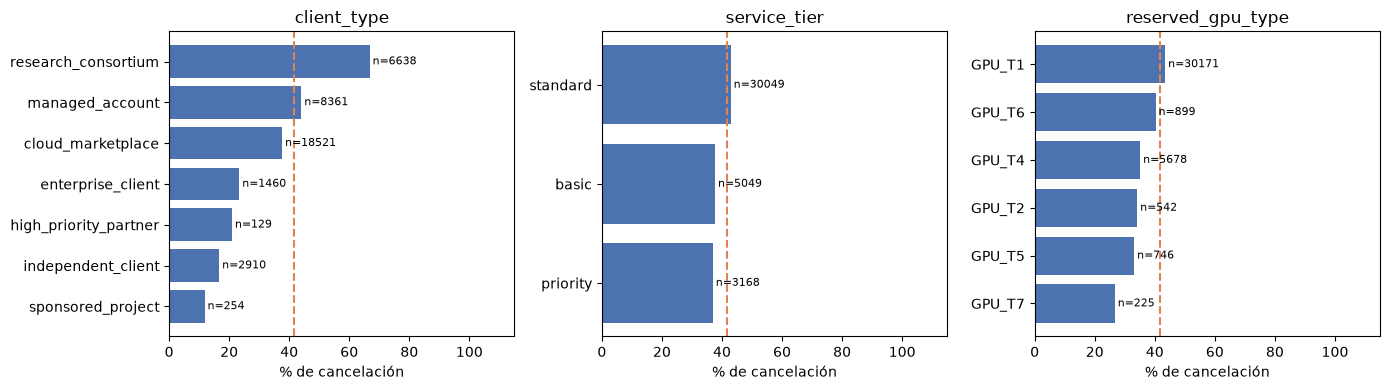

In [189]:
# ANÁLISIS POR COHORTES

cols_cohortes = ["client_type", "service_tier", "reserved_gpu_type"]

for col in cols_cohortes:

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa_cancelacion=("canceled_job", "mean"),
    )
    # El peso de la cohorte importa tanto como su tasa
    tabla["porc_del_train"] = tabla["reservas"] / len(train) * 100

    print(f"\n=== {col} ===")
    print(tabla.sort_values("reservas", ascending=False).round(3))

# Gráfico: tasa de cancelación de cada cohorte, con su tamaño al lado
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, cols_cohortes):

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa=("canceled_job", "mean"),
    )
    # Solo cohortes con suficientes casos como para que la tasa sea confiable
    tabla = tabla[tabla["reservas"] >= minimo_reservas].sort_values("tasa")

    ax.barh(tabla.index, tabla["tasa"] * 100, color="#4C72B0")

    # Cantidad de reservas al lado de cada barra
    for i, (t, n) in enumerate(zip(tabla["tasa"], tabla["reservas"])):
        ax.text(t * 100 + 1, i, f"n={n}", va="center", fontsize=8)

    # Línea de referencia con la tasa global
    ax.axvline(train["canceled_job"].mean() * 100, color="#DD8452", linestyle="--")

    ax.set_xlim(0, 115)
    ax.set_xlabel("% de cancelación")
    ax.set_title(col)

plt.tight_layout()
plt.show()

La línea naranja marca la tasa global de cancelación del train (41,7%).

- **`client_type`** es la cohorte más útil de las tres. `cloud_marketplace` concentra el **48,4%** de las reservas y cancela por debajo del promedio (37,6%), mientras que `research_consortium` es el **17,3%** del train y cancela el **66,8%**. Son dos poblaciones con comportamientos muy distintos.
- **`service_tier`** casi no discrimina: `standard` (78,5% de las reservas) cancela 42,9% y `priority` 36,9%. La diferencia es chica comparada con las otras cohortes.
- **`reserved_gpu_type`** está muy concentrada: `GPU_T1` es el **78,8%** del train. El resto de los tipos tienen tasas entre 26,7% y 40,3%, pero cada uno representa pocos casos.

Las cohortes `unknown` en `client_type` (1 reserva), `enterprise` en `service_tier` (8) y `GPU_T12` / `GPU_T3` en `reserved_gpu_type` (5 y 8) tienen demasiado pocos casos para sacar conclusiones. Se agruparán en "otros" durante el preprocesamiento.

### 4.4 Outliers y valores atípicos

Siguiendo el criterio del rango intercuartílico (IQR), se consideran atípicos los valores por encima de `Q3 + 1,5 × IQR`.

                          mediana  maximo  limite_IQR  n_atipicos
variable                                                         
hours_before_execution      71.00   629.0      360.50        1363
estimated_cost_per_hour      4.97   270.0        9.75        1072
queue_wait_time              0.00   391.0        0.00        1743
num_background_processes     0.00    10.0        0.00         173


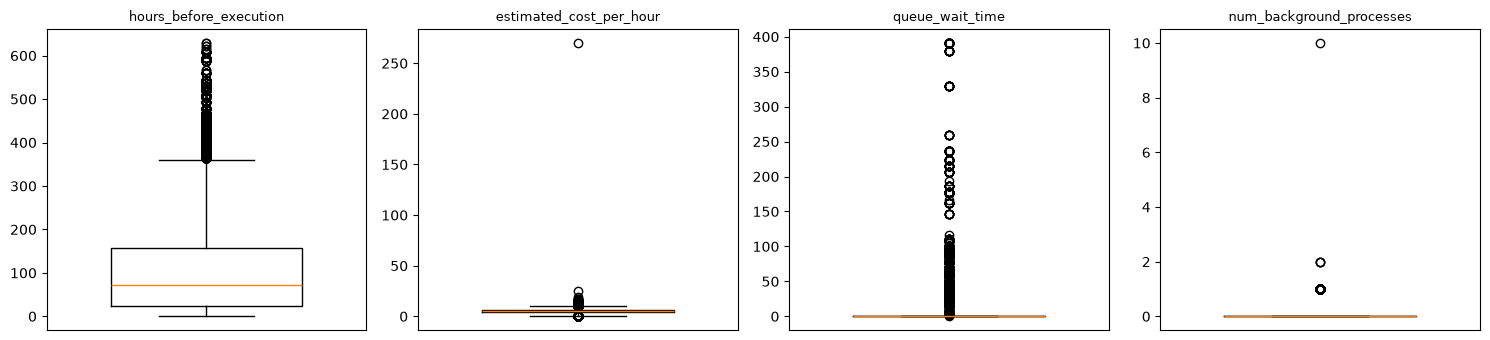


num_background_processes:
num_background_processes
0     38101
1       169
2         3
10        1
Name: count, dtype: int64

estimated_cost_per_hour:
  reservas con costo 0: 601
  reservas con costo mayor a 100: 1


In [190]:
# OUTLIERS: CRITERIO DEL RANGO INTERCUARTÍLICO (IQR)

cols_revisar = [
    "hours_before_execution",
    "estimated_cost_per_hour",
    "queue_wait_time",
    "num_background_processes",
]

filas_iqr = []

for col in cols_revisar:

    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1

    # Todo lo que supere este límite se considera atípico
    limite_superior = q3 + 1.5 * iqr

    filas_iqr.append({
        "variable": col,
        "mediana": train[col].median(),
        "maximo": train[col].max(),
        "limite_IQR": limite_superior,
        "n_atipicos": int((train[col] > limite_superior).sum()),
    })

print(pd.DataFrame(filas_iqr).set_index("variable").round(2))

# Boxplots para ver la forma de cada distribución
fig, axes = plt.subplots(1, len(cols_revisar), figsize=(15, 3.5))

for ax, col in zip(axes, cols_revisar):
    ax.boxplot(train[col].dropna(), widths=0.6)
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

# Miramos de cerca los dos casos sospechosos de ser errores de carga
print("\nnum_background_processes:")
print(train["num_background_processes"].value_counts().sort_index())

print("\nestimated_cost_per_hour:")
print("  reservas con costo 0:", (train["estimated_cost_per_hour"] == 0).sum())
print("  reservas con costo mayor a 100:", (train["estimated_cost_per_hour"] > 100).sum())

Conviene distinguir tres situaciones:

- **Valores extremos pero plausibles**: `hours_before_execution` llega a 629 horas, que corresponde a reservas hechas con mucha anticipación pero perfectamente posibles. `queue_wait_time` tiene mediana 0, así que el criterio IQR marca como atípica cualquier espera mayor a cero, lo cual no tiene sentido tratar como error. En estos casos los valores se conservan, porque son parte de la variabilidad real del problema.
- **Errores de carga**: en `num_background_processes`, casi todas las reservas tienen entre 0 y 2 procesos, pero aparece una con 10. En `estimated_cost_per_hour` hay una reserva con 270 USD por hora, cuando el segundo valor más alto es 25,5. En ambos casos el resto de la reserva es completamente común (pocas horas, pocos procesos, un solo experimento), así que estos valores no son coherentes con el pedido y probablemente sean errores de tipeo.
- **Costos en 0**: hay 601 reservas con costo 0. No se tratan como error porque tienen una explicación, que se verifica a continuación.

#### Tratamiento de los errores de carga

Para corregir los errores de carga se define una regla con un umbral por columna: todo valor que supere ese umbral se considera un error y se reemplaza por un valor faltante. Después, el pipeline imputa ese faltante con la mediana de train, igual que al resto de los nulos. De esta forma, la reserva conserva toda la información válida del resto de sus columnas y solo se corrige el dato incorrecto.

Se aplica solo a las dos columnas donde se detectaron errores, con umbrales definidos a partir de los valores observados:

- **`num_background_processes` mayor a 2**: salvo el caso detectado, ninguna reserva supera los 2 procesos.
- **`estimated_cost_per_hour` mayor a 50 USD**: el segundo valor más alto es 25,5 USD, así que el umbral deja margen para costos altos legítimos y solo afecta al valor anómalo.

In [191]:
# REGLA PARA LOS ERRORES DE CARGA

# Valores por encima de estos umbrales se consideran errores de carga.
# Este diccionario se usará después dentro del pipeline.
umbrales_error = {
    "num_background_processes": 2,
    "estimated_cost_per_hour": 50,
}

for col, umbral in umbrales_error.items():
    valores_ordenados = train[col].sort_values(ascending=False).unique()
    print(f"\n{col}:")
    print("  valores más altos:", valores_ordenados[:4])
    print(f"  reservas por encima de {umbral}:", int((train[col] > umbral).sum()))

# Verificamos la explicación de los costos en 0
costo_cero = train[train["estimated_cost_per_hour"] == 0]
horas_totales = train["peak_gpu_hours"] + train["offpeak_gpu_hours"]

patrocinados = train[train["client_type"] == "sponsored_project"]
sin_horas = train[horas_totales == 0]

print("\nReservas con costo 0:", len(costo_cero))
print("% de proyectos patrocinados con costo 0:",
      round((patrocinados["estimated_cost_per_hour"] == 0).mean() * 100, 1))
print("% de reservas con 0 horas de GPU que tienen costo 0:",
      round((sin_horas["estimated_cost_per_hour"] == 0).mean() * 100, 1))


num_background_processes:
  valores más altos: [10  2  1  0]
  reservas por encima de 2: 1

estimated_cost_per_hour:
  valores más altos: [270.      25.5     18.6165  17.4815]
  reservas por encima de 50: 1

Reservas con costo 0: 601
% de proyectos patrocinados con costo 0: 92.9
% de reservas con 0 horas de GPU que tienen costo 0: 100.0


La regla afecta a una sola reserva en cada columna, así que no modifica el resto de los datos.

Los costos en 0, en cambio, tienen una explicación razonable:

- **Proyectos patrocinados**: el 92,9% de las reservas `sponsored_project` tiene costo 0. Tiene sentido, porque el costo lo cubre un sponsor y no el cliente.
- **Reservas sin horas de GPU**: el 100% de las reservas con 0 horas tiene costo 0, porque sin horas reservadas no hay costo.

Por eso los costos en 0 se conservan como valores válidos.

### 4.5 Variables con información posterior a la reserva

En la sección 1 se eliminaron `execution_status` y `execution_status_date` por contener el resultado de la reserva. Queda una variable con un problema parecido pero más sutil: **`assigned_gpu_type`**, el tipo de GPU finalmente asignado.

In [192]:
# ¿assigned_gpu_type APORTA INFORMACIÓN POSTERIOR A LA RESERVA?

# Marcamos si la GPU asignada es distinta de la que se había reservado
gpu_cambiada = train["assigned_gpu_type"] != train["reserved_gpu_type"]

tabla_gpu = train.groupby(gpu_cambiada).agg(
    reservas=("canceled_job", "size"),
    tasa_cancelacion=("canceled_job", "mean"),
)
tabla_gpu.index = ["Misma GPU que la reservada", "Le cambiaron la GPU"]

print(tabla_gpu.round(3))

                            reservas  tasa_cancelacion
Misma GPU que la reservada     34777             0.453
Le cambiaron la GPU             3497             0.064


El resultado es llamativo: cuando la GPU asignada difiere de la reservada (3.497 reservas, el 9,1% del train), la tasa de cancelación baja al 6,4%, frente al 45,3% cuando no hubo cambio.

La variable no tiene valores faltantes: las 47.842 reservas tienen un tipo de GPU asignado, incluidas las canceladas. No se trata entonces de un campo que solo se completa para las reservas que llegan a ejecutarse.

Lo que no puede determinarse con los datos disponibles es en qué momento queda fijado ese valor. Si la asignación definitiva se decide al crear la reserva, la variable es legítima y la diferencia observada refleja que ciertos perfiles de reserva, los que requieren un cambio de recurso, son más estables. Si en cambio se decide cerca de la ejecución, la diferencia sería consecuencia de no haber cancelado y no una característica conocida al momento de predecir.

No hay en el dataset ninguna marca temporal que permita distinguir entre las dos situaciones. Se decide conservarla, dado que forma parte de la información disponible en la entrada, dejando registrada la limitación: si el valor se fijara tarde, el rendimiento estimado sería optimista respecto al que tendría el sistema en producción.

En la etapa de optimización se entrena con y sin la variable, para cuantificar cuánto del rendimiento depende de ella.

### 4.6 Conclusiones del análisis exploratorio

| Hallazgo | Decisión |
|---|---|
| `total_gpu_hours`, `total_processes` y `execution_week` quedan determinadas por otras variables | Se eliminan |
| `hours_before_execution` es la numérica más informativa (información mutua 0,106) | Se conserva; candidata a transformaciones |
| `estimated_cost_per_hour` tiene correlación casi nula pero es la segunda en información mutua | Se conserva: la relación existe pero no es lineal |
| `reservation_commitment` es la categórica más asociada al target (V de Cramér 0,52), por el 99,8% de `locked_allocation` | Se conserva: es información contractual conocida al reservar |
| `orchestration_agent_id` va del 6,5% al 100% de cancelación según el agente | Se conserva y se trata como categórica |
| `organization_id` casi no discrimina: el 95% sin organización cancela como el promedio | Se conserva, principalmente como indicador de si hay organización |
| `client_type` contiene casi toda la información de `request_channel` y agrega la suya | Se conservan las dos; la redundancia se evalúa en la optimización |
| `client_type` separa fuerte (66,8% contra 11,8%); `service_tier` casi no separa (V de Cramér 0,05) | `client_type` es la cohorte útil para el análisis de errores |
| Dos valores extremos aislados parecen errores de carga | Se corrigen con una regla; afectan una reserva por columna |
| Los costos en 0 se explican por proyectos patrocinados y reservas sin horas de GPU | Se conservan como valores válidos |
| No puede determinarse en qué momento queda fijado `assigned_gpu_type` | Se conserva y se mide su impacto por separado |

## 5. Preprocesamiento

Todas las transformaciones se agrupan en un `Pipeline` de scikit-learn: una secuencia de pasos (imputar faltantes, escalar, codificar categóricas y entrenar el modelo) que se aplica siempre en el mismo orden. Usarlo tiene tres ventajas:

- **Evita el data leakage**: los valores que necesita cada paso, como la mediana para imputar o la media para escalar, se calculan solo con train y después se aplican a validación y test.
- **Se reutiliza en la función predictora**: los datos nuevos pasan por exactamente los mismos pasos que los de entrenamiento, sin repetir código.
- **Se integra con la validación cruzada**: en cada fold, el pipeline se vuelve a ajustar solo con los datos de entrenamiento de ese fold.

### 5.1 Grupos de columnas

Las columnas se separan en tres grupos, porque cada uno necesita un tratamiento distinto. Las variables redundantes ya se eliminaron en la sección 4.1.

In [193]:
# GRUPOS DE COLUMNAS SEGÚN SU TRATAMIENTO

# Identificadores: pandas los lee como números, pero son etiquetas.
# Además concentran casi todos los valores faltantes del dataset.
cols_identificadores = ["orchestration_agent_id", "organization_id"]

# Nominales: las categóricas de texto, definidas en la sección 2.4
cols_nominales = list(cols_categoricas)

# Numéricas: todo lo que no entra en los grupos anteriores
cols_numericas = [c for c in X_train.columns
                  if c not in cols_identificadores + cols_nominales]

resumen_grupos = pd.DataFrame({
    "grupo": ["Numéricas", "Nominales", "Identificadores"],
    "columnas": [len(cols_numericas), len(cols_nominales),
                 len(cols_identificadores)],
})

print(resumen_grupos.to_string(index=False))

print("\nNuméricas:", cols_numericas)
print("\nNominales:", cols_nominales)

          grupo  columnas
      Numéricas        18
      Nominales         8
Identificadores         2

Numéricas: ['hours_before_execution', 'execution_year', 'execution_month', 'execution_day', 'peak_gpu_hours', 'offpeak_gpu_hours', 'num_primary_processes', 'num_auxiliary_processes', 'num_background_processes', 'returning_client', 'previous_job_cancellations', 'successful_previous_jobs', 'resource_modifications', 'queue_wait_time', 'estimated_cost_per_hour', 'reserved_storage_units', 'special_resource_requests', 'high_value_client']

Nominales: ['service_tier', 'client_type', 'request_channel', 'reserved_gpu_type', 'assigned_gpu_type', 'reservation_commitment', 'workload_profile', 'client_region']


### 5.2 Construcción del pipeline

El pipeline procesa cada reserva en cuatro pasos.

**Paso 1: corregir los errores de carga.** Los valores que superan los umbrales definidos en la sección 4.4 (más de 2 procesos de mantenimiento o un costo mayor a 50 USD por hora) se reemplazan por valores faltantes. Así, en el paso 3 se completan con la mediana como cualquier otro nulo.

**Paso 2: separar las columnas en grupos.** Las columnas se dividen en numéricas, nominales (categóricas de texto) e identificadores, porque cada grupo necesita un tratamiento distinto.

**Paso 3: completar los valores faltantes.** En las numéricas, los faltantes se completan con la mediana de train, que a diferencia del promedio no se ve afectada por los valores extremos detectados en la sección 4.4. En las nominales se usa la categoría más frecuente. En los identificadores, el faltante se reemplaza por `-1`, que pasa a funcionar como una categoría más: "sin agente" o "sin organización".

**Paso 4: transformar los valores.** Las variables numéricas se escalan con `StandardScaler`, que las lleva a todas a la misma escala (media 0 y desvío 1).

Las nominales y los identificadores se transforman con `OneHotEncoder`, que convierte cada categoría en una columna de 0 y 1, ya que los modelos solo trabajan con números. Por ejemplo, `service_tier` se convierte en tres columnas (`basic`, `standard` y `priority`), y cada reserva tiene un 1 en la que le corresponde.

El `OneHotEncoder` se configura con dos opciones. La primera, `min_frequency=0.01`, agrupa en una sola columna de "otros" todas las categorías que representan menos del 1% de las reservas. Así, los 149 países de `client_region` y los 194 agentes no generan una columna cada uno. La segunda, `handle_unknown="infrequent_if_exist"`, hace que una categoría que no apareció en train, como un país nuevo, se asigne a esa misma columna de "otros" en lugar de producir un error en la función predictora.

In [194]:
# PIPELINE DE PREPROCESAMIENTO

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer


# PASO 1: CORRECCIÓN DE LOS ERRORES DE CARGA (sección 4.4)

def marcar_errores_de_carga(X, umbrales):
    """
    Reemplaza por faltante (NaN) todo valor que supere el umbral de su columna.
    Después, el SimpleImputer de las numéricas completa esos faltantes con la mediana.
    """
    X = X.copy()  # no modificamos el DataFrame original
    for col, umbral in umbrales.items():
        X.loc[X[col] > umbral, col] = np.nan
    return X


# FunctionTransformer convierte la función en un paso del pipeline
corregir_errores = FunctionTransformer(
    marcar_errores_de_carga,
    kw_args={"umbrales": umbrales_error},
)


# PASOS 2 A 4: IMPUTACIÓN Y TRANSFORMACIÓN POR GRUPO DE COLUMNAS
pipe_numericas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

pipe_nominales = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=0.01,
                                sparse_output=False)),
])

pipe_identificadores = Pipeline([
    # El -1 representa "sin agente" / "sin organización"
    ("imputar", SimpleImputer(strategy="constant", fill_value=-1)),
    ("codificar", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=0.01,
                                sparse_output=False)),
])

# remainder="drop" descarta cualquier columna que no esté en los grupos anteriores
transformar_columnas = ColumnTransformer([
    ("numericas", pipe_numericas, cols_numericas),
    ("nominales", pipe_nominales, cols_nominales),
    ("identificadores", pipe_identificadores, cols_identificadores),
], remainder="drop")


# PREPROCESADOR COMPLETO: primero se corrigen los errores, después se transforma
preprocesador = Pipeline([
    ("corregir_errores", corregir_errores),
    ("transformar_columnas", transformar_columnas),
])

# Lo ajustamos SOLO con train
X_train_pre = preprocesador.fit_transform(X_train)

print("X_train:", X_train.shape, "->", X_train_pre.shape)
print("Valores faltantes después de preprocesar:", int(np.isnan(X_train_pre).sum()))

# Verificamos que la corrección se aplicó: ningún valor debe superar su umbral
X_corregido = preprocesador.named_steps["corregir_errores"].transform(X_train)

print("\nVerificación de la corrección de errores de carga:")
for col, umbral in umbrales_error.items():
    convertidos = int(X_corregido[col].isna().sum() - X_train[col].isna().sum())
    print(f"  {col}: máximo antes = {X_train[col].max():g}, "
          f"máximo después = {X_corregido[col].max():g}, "
          f"valores convertidos en faltante = {convertidos}")

# Cuántas columnas generó cada variable de alta cardinalidad
nombres_columnas = preprocesador.named_steps["transformar_columnas"].get_feature_names_out()

print("\nColumnas generadas por las variables de alta cardinalidad:")
for col in ["client_region", "orchestration_agent_id", "organization_id"]:
    print(f"  {col}: {sum(col in n for n in nombres_columnas)} columnas")

X_train: (38274, 28) -> (38274, 83)
Valores faltantes después de preprocesar: 0

Verificación de la corrección de errores de carga:
  num_background_processes: máximo antes = 10, máximo después = 2, valores convertidos en faltante = 1
  estimated_cost_per_hour: máximo antes = 270, máximo después = 25.5, valores convertidos en faltante = 1

Columnas generadas por las variables de alta cardinalidad:
  client_region: 15 columnas
  orchestration_agent_id: 14 columnas
  organization_id: 3 columnas


El pipeline transforma las 28 columnas originales en 83 columnas numéricas, sin valores faltantes. La verificación confirma que la corrección de errores de carga se aplicó: en cada columna se convirtió un único valor en faltante, que luego se completa con la mediana. Una vez quitados esos valores, el máximo de `num_background_processes` es 2 y el de `estimated_cost_per_hour` es 25,5, ambos valores reales del dataset. La agrupación de categorías poco frecuentes reduce `client_region` de 149 países a 15 columnas y los 194 agentes de orquestación a 14.

Dos aclaraciones sobre cómo se usa de acá en adelante:

- El `preprocesador` se ajustó con train solo para verificar que funciona. En la validación cruzada no se usará este objeto ya ajustado: se lo encadenará con cada clasificador dentro de un `Pipeline` completo, de modo que en cada fold se reajuste únicamente con los datos de entrenamiento de ese fold.
- `X_test` todavía no se tocó. Se transformará recién en la evaluación final.

Con esto queda cerrada la etapa de preprocesamiento y análisis exploratorio. El siguiente paso es entrenar los primeros clasificadores y establecer un baseline.

## 6. Clasificadores y baseline

Con los datos ya preparados, el objetivo de esta sección es establecer un punto de comparación: un modelo razonable, elegido y ajustado con criterio, contra el cual medir después cualquier intento de mejora. Sin ese punto de referencia no hay forma de saber si una modificación posterior sirve o no.



### 6.1 Métricas de evaluación

Se usan dos métricas, porque miden cosas distintas y ninguna alcanza sola.

La primera es la **balanced accuracy**, que promedia el recall de cada clase: cuántas cancelaciones detecta sobre el total de cancelaciones, y cuántas no cancelaciones detecta sobre el total de no cancelaciones. La accuracy común no sirve acá porque el 58,3% de las reservas no se cancela, así que un modelo que responda siempre "no cancelada" ya acierta casi seis de cada diez veces sin haber aprendido nada. La balanced accuracy castiga eso: un modelo que ignore una clase entera obtiene 0,5, que es lo mismo que responder al azar.

La segunda es el **ROC-AUC**. Los modelos no devuelven una respuesta sino una probabilidad, y para convertirla en decisión hace falta fijar un umbral. La balanced accuracy depende de dónde se ponga ese umbral; el ROC-AUC no, porque recorre todos los umbrales posibles y mide qué tan bien el modelo ordena las reservas de menor a mayor riesgo. Un valor de 0,5 equivale a ordenar al azar y 1 a un ordenamiento perfecto.

Las dos juntas permiten distinguir dos situaciones que de otro modo se confunden: un modelo que separa mal las clases, y uno que las separa bien pero con el umbral mal ubicado. El primero necesita otro modelo o mejores variables; el segundo solo necesita mover el umbral.

De las dos, la balanced accuracy es la que se usa para tomar decisiones: comparar modelos, elegir hiperparámetros y definir el baseline, ya que además es la métrica de la competencia. El ROC-AUC se usa como complemento para diagnosticar por qué un modelo rinde como rinde.


### 6.2 Esquema de validación cruzada

Los modelos se evalúan con validación cruzada de 5 folds sobre train. En cada iteración el modelo se entrena con cuatro quintos de los datos y se evalúa sobre el quinto restante, de modo que cada reserva se usa para validar exactamente una vez.

Se usa `StratifiedGroupKFold` con los mismos grupos del split de la sección 3, por dos motivos. La parte estratificada mantiene la proporción de cancelaciones en cada fold, que de otro modo podría variar bastante por azar. La parte de grupos impide que dos reservas idénticas queden una en entrenamiento y otra en validación: si eso ocurriera, el modelo estaría siendo evaluado sobre filas que ya vio, y la métrica saldría más alta de lo que corresponde.

Esta es la misma lógica con la que se separó el test, así que la estimación de la validación cruzada es comparable con lo que después dará la evaluación final.

El preprocesamiento se incluye dentro del pipeline en lugar de aplicarse antes. Así, en cada fold, la mediana para imputar, la media y el desvío para escalar y las categorías conocidas se calculan solamente con los datos de entrenamiento de ese fold.

In [195]:
# ESQUEMA DE VALIDACIÓN CRUZADA

from sklearn.model_selection import cross_validate

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

metricas = ["balanced_accuracy", "roc_auc"]

# Verificamos que cada fold mantenga la proporción de cancelaciones
# y que ningún grupo de duplicados quede partido entre train y validación
filas = []
for i, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train, groups=grupos_train), start=1):
    compartidos = set(grupos_train.iloc[idx_tr]) & set(grupos_train.iloc[idx_val])
    filas.append({
        "fold": i,
        "train": len(idx_tr),
        "validacion": len(idx_val),
        "porc_canceladas_val": round(y_train.iloc[idx_val].mean() * 100, 2),
        "grupos_compartidos": len(compartidos),
    })

print(pd.DataFrame(filas).to_string(index=False))

 fold  train  validacion  porc_canceladas_val  grupos_compartidos
    1  30621        7653                41.71                   0
    2  30613        7661                41.72                   0
    3  30620        7654                41.72                   0
    4  30621        7653                41.71                   0
    5  30621        7653                41.71                   0


Los cinco folds quedan parejos, con la proporción de cancelaciones casi idéntica entre ellos, y ningún grupo de duplicados aparece a la vez en entrenamiento y validación.

### 6.3 Comparación de familias de clasificadores

Antes de ajustar hiperparámetros hay que decidir qué tipo de modelo usar. Para eso se entrena un representante de cada familia:

- Regresión logística: modelo lineal, separa las clases con una frontera recta.
- Árbol de decisión: divide los datos con reglas sucesivas sobre las variables.
- k vecinos: clasifica cada reserva según las reservas más parecidas de entrenamiento.
- Naive Bayes: modelo probabilístico que asume que las variables son independientes entre sí.
- Random Forest: ensamble que combina muchos árboles entrenados sobre muestras distintas.

Todos se evalúan con el mismo preprocesamiento, el mismo esquema de validación cruzada y sus hiperparámetros por defecto. Así la comparación es justa: ninguno recibe más ajuste que otro, y las diferencias reflejan qué familia se adapta mejor a estos datos. Las únicas excepciones son `max_iter=2000` en la regresión logística, que solo asegura que el algoritmo converja, y `n_estimators=200` en el Random Forest, porque agregar árboles estabiliza el resultado sin hacer el modelo más complejo.

La familia que mejor rinda es la que se ajusta en la sección 6.4.

In [196]:
# COMPARACIÓN DE FAMILIAS DE CLASIFICADORES

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Un representante de cada familia vista en la materia, con sus valores por defecto
candidatos = {
    "Regresión logística": LogisticRegression(max_iter=2000, random_state=42),
    "Árbol de decisión": DecisionTreeClassifier(random_state=42),
    "k vecinos": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

filas = []
for nombre, modelo in candidatos.items():

    # El preprocesamiento va adentro del pipeline, así se reajusta en cada fold.
    # El paralelismo lo hace cross_validate (n_jobs=-1), no cada modelo
    pipe = Pipeline([("preprocesar", preprocesador), ("modelo", modelo)])

    r = cross_validate(pipe, X_train, y_train, cv=cv, groups=grupos_train,
                       scoring=metricas, n_jobs=-1)

    filas.append({
        "modelo": nombre,
        "BA": r["test_balanced_accuracy"].mean(),
        "BA_desvio": r["test_balanced_accuracy"].std(),
        "ROC_AUC": r["test_roc_auc"].mean(),
    })

comparacion_modelos = pd.DataFrame(filas).set_index("modelo").sort_values("BA", ascending=False)
comparacion_modelos.round(4)

,BA,BA_desvio,ROC_AUC
modelo,,,
Random Forest,0.8435,0.0057,0.9375
Árbol de decisión,0.8089,0.0044,0.8104
Regresión logística,0.8041,0.0068,0.9007
k vecinos,0.7864,0.0074,0.8583
Naive Bayes,0.6698,0.0106,0.7897


El Random Forest gana con claridad en las dos métricas: 0,8414 de balanced accuracy contra 0,8074 del segundo. Era esperable, porque son datos tabulares con variables de naturalezas muy distintas, mezcladas entre numéricas y categóricas, y los métodos basados en árboles manejan bien esa heterogeneidad al evaluar cada variable por separado en cada corte.

El resto deja ver bastante sobre los datos:

- El árbol de decisión tiene 0,8074 de balanced accuracy pero apenas 0,8089 de ROC-AUC, muy por debajo de la logística, que separa peor pero tiene 0,9007. Es el caso que anticipábamos al elegir las métricas: un árbol sin podar lleva cada hoja hasta la pureza y devuelve probabilidades pegadas a 0 o a 1, así que clasifica razonablemente pero no logra ordenar las reservas por riesgo. Las dos métricas no se contradicen, miden capacidades distintas.
- Naive Bayes es el peor por lejos, con 0,6698. Asume que las variables son independientes entre sí dado el target, y en la sección 4.2 vimos que eso no se cumple: hay pares con asociaciones muy fuertes, como `client_type` con `request_channel`.
- k vecinos queda en 0,7864. El espacio tiene 83 dimensiones, la mayoría columnas binarias del one-hot, y en esas condiciones las distancias entre puntos se vuelven parecidas entre sí y la noción de vecindad pierde poder.

Se elige el Random Forest para ajustar sus hiperparámetros.

### 6.4 Ajuste de hiperparámetros

Se ajustan cuatro hiperparámetros del Random Forest:

- `max_features`: proporción de variables que mira cada árbol en cada corte. Es lo que diferencia a un Random Forest de un conjunto de árboles comunes: cuanto más bajo, más distintos son los árboles entre sí.
- `max_depth`: profundidad máxima de cada árbol.
- `min_samples_leaf`: cantidad mínima de reservas en cada hoja. Junto con la profundidad, controla cuánto puede especializarse cada árbol.
- `n_estimators`: cantidad de árboles. No cambia la complejidad de cada árbol, solo cuántos se promedian.

En lugar de probar todas las combinaciones, se ajusta un hiperparámetro por vez. Cada uno se prueba con 5 valores, y el que da mejor balanced accuracy en validación cruzada queda fijo para las pruebas siguientes. Así se prueban 20 configuraciones en lugar de las 625 de una grilla completa. La desventaja es que no se captura cómo interactúan los hiperparámetros: el valor elegido para cada uno depende de los que ya estaban fijos.

Se empieza por `max_features`, que es el hiperparámetro propio del Random Forest, se sigue con los dos que controlan el tamaño de cada árbol y se termina con `n_estimators`, que solo estabiliza el promedio. El punto de partida es el Random Forest de la sección 6.3.

Para cada hiperparámetro se grafica su curva de validación: la balanced accuracy en train y en validación para cada valor probado. Si la validación mejora al aumentar la complejidad, el modelo todavía tiene margen; si train sigue subiendo y la validación baja, empieza el sobreajuste.

=== max_features: se elige 0.5 ===
valor  BA_train  BA_validacion  desvio_validacion
  0.1    0.9966         0.8430             0.0050
  0.2    0.9966         0.8458             0.0051
  0.3    0.9966         0.8432             0.0090
  0.5    0.9966         0.8471             0.0109
  0.7    0.9966         0.8465             0.0080 

=== max_depth: se elige None ===
valor  BA_train  BA_validacion  desvio_validacion
   10    0.8591         0.8340             0.0110
   15    0.9081         0.8407             0.0110
   20    0.9622         0.8450             0.0103
   30    0.9965         0.8445             0.0104
 None    0.9966         0.8471             0.0109 

=== min_samples_leaf: se elige 1 ===
valor  BA_train  BA_validacion  desvio_validacion
    1    0.9966         0.8471             0.0109
    2    0.9842         0.8429             0.0101
    3    0.9642         0.8426             0.0086
    5    0.9365         0.8415             0.0090
   10    0.9015         0.8417           

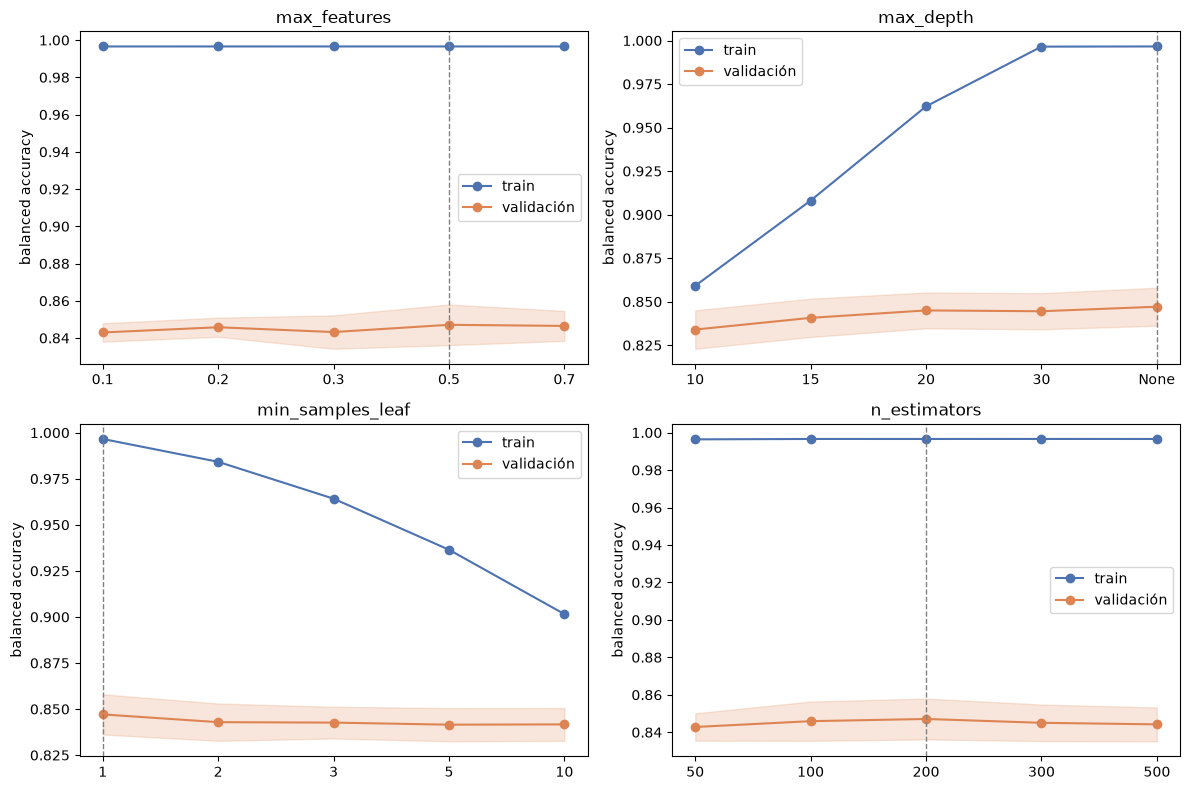

Hiperparámetros elegidos: {'max_features': 0.5, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}


In [197]:
# AJUSTE DE HIPERPARÁMETROS: CURVAS DE VALIDACIÓN

from sklearn.model_selection import validation_curve

# Valores a probar para cada hiperparámetro, en el orden en que se ajustan
valores_a_probar = {
    "max_features": [0.1, 0.2, 0.3, 0.5, 0.7],
    "max_depth": [10, 15, 20, 30, None],
    "min_samples_leaf": [1, 2, 3, 5, 10],
    "n_estimators": [50, 100, 200, 300, 500],
}

# Punto de partida: el Random Forest de la comparación de la sección 6.3.
# Cada vez que se ajusta un hiperparámetro, su mejor valor reemplaza al de acá
# y queda fijo para las pruebas siguientes.
mejores = {"max_features": "sqrt", "max_depth": None, "min_samples_leaf": 1, "n_estimators": 200}

curvas = {}
for param, valores in valores_a_probar.items():

    # Sin n_jobs en el Random Forest: el paralelismo ya lo hace validation_curve
    pipe = Pipeline([("preprocesar", preprocesador),
                     ("modelo", RandomForestClassifier(random_state=42, **mejores))])

    scores_train, scores_val = validation_curve(
        pipe, X_train, y_train,
        param_name=f"modelo__{param}", param_range=valores,
        cv=cv, groups=grupos_train, scoring="balanced_accuracy", n_jobs=-1,
    )

    curvas[param] = pd.DataFrame({
        "valor": [str(v) for v in valores],
        "BA_train": scores_train.mean(axis=1),
        "BA_validacion": scores_val.mean(axis=1),
        "desvio_validacion": scores_val.std(axis=1),
    })
    mejores[param] = valores[int(np.argmax(scores_val.mean(axis=1)))]

    print(f"=== {param}: se elige {mejores[param]} ===")
    print(curvas[param].round(4).to_string(index=False), "\n")

# Una curva por hiperparámetro: train y validación, con el valor elegido marcado
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (param, tabla) in zip(axes.ravel(), curvas.items()):
    x = range(len(tabla))
    ax.plot(x, tabla["BA_train"], "o-", color="#4C72B0", label="train")
    ax.plot(x, tabla["BA_validacion"], "o-", color="#DD8452", label="validación")
    ax.fill_between(x, tabla["BA_validacion"] - tabla["desvio_validacion"],
                    tabla["BA_validacion"] + tabla["desvio_validacion"],
                    color="#DD8452", alpha=0.2)

    elegido = tabla["valor"].tolist().index(str(mejores[param]))
    ax.axvline(elegido, color="gray", linestyle="--", linewidth=1)

    ax.set_xticks(list(x))
    ax.set_xticklabels(tabla["valor"])
    ax.set_title(param)
    ax.set_ylabel("balanced accuracy")
    ax.legend()

plt.tight_layout()
plt.show()

print("Hiperparámetros elegidos:", mejores)

Resultados de cada curva:

- `max_features`: solo 0,1, que equivale aproximadamente a la raíz cuadrada usada por defecto, es peor (0,8413). Entre 0,2 y 0,7 todos dan alrededor de 0,846. Se elige 0,2.
- `max_depth`: la validación mejora al permitir árboles más profundos, de 0,8190 con 10 niveles a 0,8466 con 30. Sin límite da lo mismo que 30. Se elige 30.
- `min_samples_leaf`: la validación empeora al exigir hojas más grandes, de 0,8466 con 1 a 0,8351 con 10. Se elige 1.
- `n_estimators`: entre 50 y 500 árboles el resultado es prácticamente el mismo. Se elige 50, el mejor y el más rápido de entrenar. La cantidad de árboles no influye en el sobreajuste: agregar árboles no hace más complejo al modelo, solo estabiliza el promedio.

El ajuste lleva la balanced accuracy de 0,8414, la del Random Forest por defecto, a 0,8473.

#### ¿El modelo elegido sobreajusta?

Con los valores elegidos, la balanced accuracy es 0,99 en train y 0,85 en validación. La brecha es grande, pero no indica sobreajuste. Un modelo sobreajusta cuando, al hacerlo más complejo, empeora sobre datos que no vio. Acá pasa lo contrario: las curvas de `max_depth` y `min_samples_leaf` muestran que los árboles más profundos y con hojas más chicas son los que mejor rinden en validación. Se podría achicar la brecha limitando los árboles, pero bajaría también la validación: con `max_depth=10` la brecha casi desaparece y la balanced accuracy cae a 0,8190. Eso no corrige un sobreajuste, sino que lleva al modelo a subajustar.

En un Random Forest esta brecha es esperable por cómo está construido. Cada árbol por separado se ajusta casi perfectamente a su muestra, es decir, sobreajusta. Pero cada uno se entrena con una muestra distinta y mira variables distintas en cada corte, así que se equivoca en reservas distintas. Al promediarlos, esos errores se compensan y el conjunto generaliza mejor que cualquier árbol individual. Por eso, para elegir, se mira el resultado en validación y no la distancia con train.

### 6.5 Umbral de decisión

El Random Forest no responde directamente "cancela" o "no cancela": devuelve una probabilidad de cancelación, y por defecto predice "cancelada" cuando esa probabilidad es 0,5 o más. Ese corte no tiene por qué ser el mejor para la balanced accuracy. Como solo el 41,7% de las reservas se cancela, puede convenir un umbral más bajo, que detecte más cancelaciones a costa de algunos errores en la otra clase.

El procedimiento, sobre el modelo con los hiperparámetros ya ajustados, es:

1. Con la misma validación cruzada, cada reserva de train recibe la probabilidad que le asigna un modelo entrenado sin ella.
2. Se prueban umbrales entre 0,20 y 0,70, de a 0,01. Para cada uno, las probabilidades se convierten en predicciones y se calcula la balanced accuracy en cada fold.
3. Se elige el umbral con mejor promedio entre folds.

Umbral 0,50: BA 0.8474 (+- 0.0108)
Umbral 0.43: BA 0.8510 (+- 0.0069)
ROC-AUC: 0.9362 (no depende del umbral)

Balanced accuracy por fold:
      umbral 0,50  umbral 0.43
fold                          
1          0.8561       0.8560
2          0.8568       0.8599
3          0.8269       0.8401
4          0.8489       0.8473
5          0.8482       0.8514


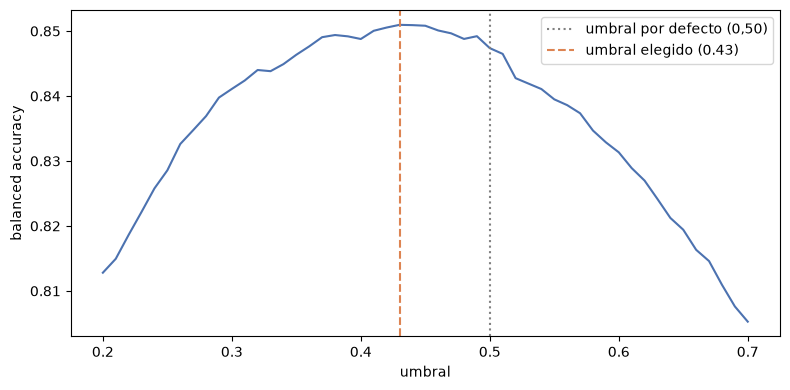

In [198]:
# AJUSTE DEL UMBRAL DE DECISIÓN

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

modelo_ajustado = Pipeline([("preprocesar", preprocesador),
                            ("modelo", RandomForestClassifier(random_state=42, **mejores))])

# Probabilidad de cancelación de cada reserva de train, predicha por el modelo
# entrenado en los otros folds. Así ninguna reserva se evalúa con un modelo que la vio.
proba_val = cross_val_predict(modelo_ajustado, X_train, y_train, cv=cv, groups=grupos_train,
                              method="predict_proba", n_jobs=-1)[:, 1]

# Índices de validación de cada fold, para medir igual que en las secciones anteriores:
# balanced accuracy por fold y después el promedio
folds_val = [idx_val for _, idx_val in cv.split(X_train, y_train, groups=grupos_train)]

def ba_por_fold(umbral):
    return np.array([balanced_accuracy_score(y_train.iloc[idx], proba_val[idx] >= umbral)
                     for idx in folds_val])

umbrales = np.round(np.arange(0.20, 0.71, 0.01), 2)
ba_umbrales = np.array([ba_por_fold(u).mean() for u in umbrales])

umbral_elegido = umbrales[int(np.argmax(ba_umbrales))]

ba_05 = ba_por_fold(0.5)
ba_elegido = ba_por_fold(umbral_elegido)
roc = np.mean([roc_auc_score(y_train.iloc[idx], proba_val[idx]) for idx in folds_val])

print(f"Umbral 0,50: BA {ba_05.mean():.4f} (+- {ba_05.std():.4f})")
print(f"Umbral {umbral_elegido:.2f}: BA {ba_elegido.mean():.4f} (+- {ba_elegido.std():.4f})")
print(f"ROC-AUC: {roc:.4f} (no depende del umbral)\n")
print("Balanced accuracy por fold:")
print(pd.DataFrame({"umbral 0,50": ba_05, f"umbral {umbral_elegido:.2f}": ba_elegido},
                   index=range(1, 6)).rename_axis("fold").round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, ba_umbrales, color="#4C72B0")
ax.axvline(0.5, color="gray", linestyle=":", label="umbral por defecto (0,50)")
ax.axvline(umbral_elegido, color="#DD8452", linestyle="--", label=f"umbral elegido ({umbral_elegido:.2f})")
ax.set_xlabel("umbral")
ax.set_ylabel("balanced accuracy")
ax.legend()
plt.tight_layout()
plt.show()

# El baseline queda definido como el Random Forest ajustado, entrenado con todo train,
# junto con su umbral: una reserva se predice como cancelada si su probabilidad es >= umbral
baseline = modelo_ajustado.fit(X_train, y_train)
umbral_baseline = umbral_elegido

El mejor umbral es 0,38, con una balanced accuracy de 0,8517, contra 0,8476 con el umbral por defecto de 0,5.

El gráfico muestra por qué. Con umbrales muy bajos, el modelo predice casi todo como cancelado y se equivoca con las reservas que no cancelan; con umbrales muy altos pasa lo contrario. Entre esos extremos se forma una meseta, entre 0,35 y 0,47, donde todos los umbrales dan alrededor de 0,851. El 0,5 queda justo afuera, donde la curva empieza a caer. Que el mejor umbral esté por debajo de 0,5 es coherente con que la clase cancelada sea la minoritaria.

La mejora es chica (0,004) y no se da en todos los folds: con 0,38 mejoran los folds 1, 2 y 5, sobre todo el 2, y empeoran levemente el 3 y el 4. Lo robusto es la conclusión general, que conviene un umbral algo menor a 0,5; el valor exacto de 0,38 no es más confiable que otro de la meseta.

#### Baseline

El baseline queda definido como el Random Forest con `max_features=0.2`, `max_depth=30`, `min_samples_leaf=1` y `n_estimators=50`, entrenado con todo train, junto con el umbral de 0,38. Una reserva se predice como cancelada si su probabilidad es 0,38 o más, así que `predictor_v1` tiene que aplicar este umbral sobre `predict_proba` y no usar `predict`, que corta en 0,5.

Resultado de cada paso, en validación cruzada:

| Paso | Balanced accuracy |
|---|---|
| Random Forest por defecto (6.3) | 0,8414 |
| Con hiperparámetros ajustados (6.4) | 0,8473 |
| Con umbral 0,38 (6.5) | 0,8517 |

El ROC-AUC final es 0,9367. Como los hiperparámetros y el umbral se eligieron con los mismos folds con los que se miden, el 0,8517 es levemente optimista. Además, por la validación por grupos, mide el rendimiento sobre reservas cuya combinación exacta de características no aparece en entrenamiento. La estimación sin sesgo la dará el test, que sigue sin tocarse.

Este es el punto de comparación para las estrategias de mejora: tienen que superar 0,8517 con el mismo esquema de validación, o justificar por qué convienen aun sin superarlo.

## 7. Análisis de errores

El baseline de la sección 6 alcanza una balanced accuracy de alrededor de 0,85. Ese número resume el rendimiento global, pero no dice en qué reservas se equivoca el modelo ni por qué. Esta sección responde esas dos preguntas: primero se identifican los errores, después se analiza en qué cohortes se concentran y qué perfil tienen. Con esa información se deciden las estrategias de mejora de la etapa de optimización.

### 7.1 Errores del baseline

Para analizar los errores hace falta comparar, para cada reserva de train, la predicción del baseline con lo que pasó en realidad. Se usan las mismas predicciones de la sección 6.5: la probabilidad de cancelación de cada reserva, calculada por un modelo que no la vio al entrenar, convertida en predicción con el umbral del baseline.

Cada predicción queda en uno de cuatro grupos:

- **VP (verdadero positivo)**: reserva cancelada que el modelo predijo como cancelada.
- **VN (verdadero negativo)**: reserva no cancelada que el modelo predijo como no cancelada.
- **FP (falso positivo)**: reserva no cancelada que el modelo predijo como cancelada.
- **FN (falso negativo)**: reserva cancelada que el modelo predijo como no cancelada.

In [213]:
# PREDICCIONES FUERA DE FOLD DEL BASELINE

from sklearn.metrics import balanced_accuracy_score, confusion_matrix

# Reutilizamos las probabilidades fuera de fold calculadas en la sección 6.5:
# cada reserva de train tiene la probabilidad que le asignó un modelo que no la vio
proba_oof = proba_val

# Aplicamos el umbral del baseline (sección 6.5) en lugar de 0,5
umbral = umbral_baseline
pred_oof = (proba_oof >= umbral).astype(int)

# Tabla de análisis: variables originales + valor real + probabilidad + predicción
analisis = X_train.copy()
analisis["real"] = y_train.values
analisis["proba"] = proba_oof
analisis["pred"] = pred_oof

# Clasificamos cada predicción en VP, VN, FP o FN
acierto = analisis["real"] == analisis["pred"]
analisis["resultado"] = np.where(
    acierto,
    np.where(analisis["real"] == 1, "VP", "VN"),
    np.where(analisis["real"] == 1, "FN", "FP"),
)

print(f"Balanced accuracy fuera de fold: {balanced_accuracy_score(y_train, pred_oof):.4f}\n")

matriz = pd.DataFrame(
    confusion_matrix(y_train, pred_oof),
    index=["Real: no cancelada", "Real: cancelada"],
    columns=["Pred: no cancelada", "Pred: cancelada"],
)
print(matriz)

conteo = analisis["resultado"].value_counts()
print(f"\nRecall de canceladas:    {conteo['VP'] / (conteo['VP'] + conteo['FN']):.3f}")
print(f"Recall de no canceladas: {conteo['VN'] / (conteo['VN'] + conteo['FP']):.3f}")
print(f"Falsos negativos: {conteo['FN']}   Falsos positivos: {conteo['FP']}")

Balanced accuracy fuera de fold: 0.8510

                    Pred: no cancelada  Pred: cancelada
Real: no cancelada               19436             2873
Real: cancelada                   2703            13262

Recall de canceladas:    0.831
Recall de no canceladas: 0.871
Falsos negativos: 2703   Falsos positivos: 2873


La balanced accuracy fuera de fold es 0,8510, la misma que se obtuvo en la sección 6.5 con el umbral ajustado, ya que se trata de las mismas predicciones.

Con este umbral, los errores quedan equilibrados entre las dos clases. El modelo reconoce el 87,1% de las reservas que no se cancelan y el 83,1% de las que sí se cancelan, con 2.703 falsos negativos (cancelaciones que el modelo no detecta) y 2.873 falsos positivos (reservas que se predicen como canceladas pero no se cancelan). 

### 7.2 Análisis por cohortes

Se calcula el rendimiento del modelo dentro de cada cohorte de `client_type`, `service_tier` y `reserved_gpu_type`. Además de la balanced accuracy, interesa qué porcentaje del total de errores concentra cada cohorte: una cohorte grande con un rendimiento algo peor puede pesar más que una chica con un rendimiento muy malo. Se consideran solo las cohortes con al menos 30 reservas.


=== client_type ===
                       reservas  porc_train  tasa_cancelacion     BA  recall_canceladas  recall_no_canceladas    FN    FP  porc_de_los_errores
client_type                                                                                                                                   
cloud_marketplace         18521      48.391             0.376  0.775              0.744                 0.805  1781  2249               72.274
managed_account            8361      21.845             0.440  0.929              0.915                 0.944   313   264               10.348
research_consortium        6638      17.343             0.668  0.939              0.969                 0.908   137   202                6.080
independent_client         2910       7.603             0.167  0.646              0.330                 0.962   325    91                7.461
enterprise_client          1460       3.815             0.234  0.830              0.704                 0.955   101    50

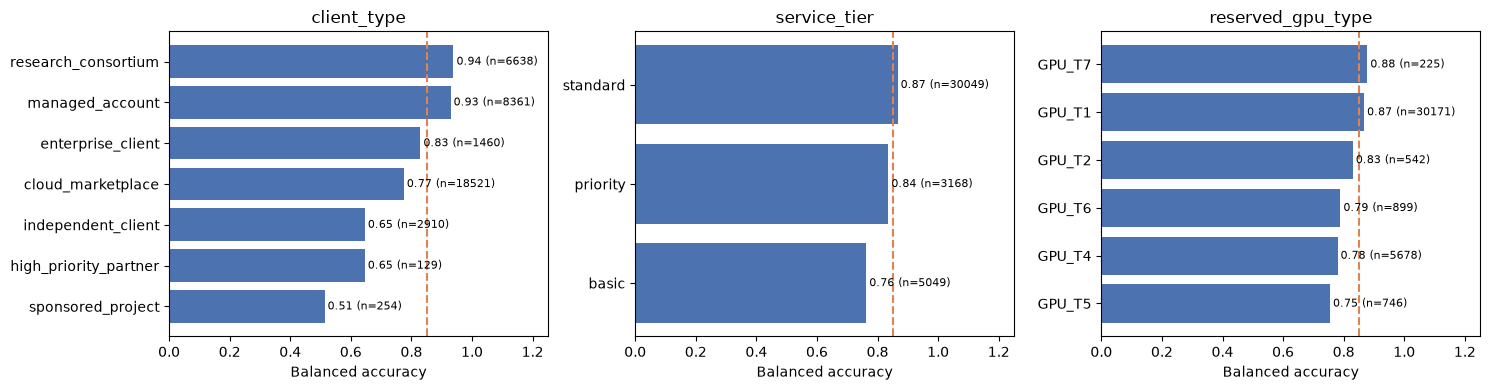

In [214]:
# RENDIMIENTO DEL MODELO POR COHORTE

def metricas_por_cohorte(datos, col, minimo=30):
    """Calcula el rendimiento del modelo dentro de cada valor de la columna col."""
    total_errores = datos["resultado"].isin(["FP", "FN"]).sum()
    filas = []

    for valor, grupo in datos.groupby(col):
        if len(grupo) < minimo:
            continue

        vp = (grupo["resultado"] == "VP").sum()
        vn = (grupo["resultado"] == "VN").sum()
        fp = (grupo["resultado"] == "FP").sum()
        fn = (grupo["resultado"] == "FN").sum()

        recall_canceladas = vp / (vp + fn) if (vp + fn) > 0 else np.nan
        recall_no_canceladas = vn / (vn + fp) if (vn + fp) > 0 else np.nan

        filas.append({
            col: valor,
            "reservas": len(grupo),
            "porc_train": len(grupo) / len(datos) * 100,
            "tasa_cancelacion": grupo["real"].mean(),
            "BA": (recall_canceladas + recall_no_canceladas) / 2,
            "recall_canceladas": recall_canceladas,
            "recall_no_canceladas": recall_no_canceladas,
            "FN": fn,
            "FP": fp,
            "porc_de_los_errores": (fp + fn) / total_errores * 100,
        })

    return pd.DataFrame(filas).set_index(col).sort_values("reservas", ascending=False)


cols_cohortes = ["client_type", "service_tier", "reserved_gpu_type"]
tablas_cohortes = {}

for col in cols_cohortes:
    tablas_cohortes[col] = metricas_por_cohorte(analisis, col)
    print(f"\n=== {col} ===")
    print(tablas_cohortes[col].round(3).to_string())

# Gráfico: balanced accuracy de cada cohorte, con la global como referencia
ba_global = balanced_accuracy_score(y_train, pred_oof)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols_cohortes):
    tabla = tablas_cohortes[col].dropna(subset=["BA"]).sort_values("BA")
    ax.barh(tabla.index.astype(str), tabla["BA"], color="#4C72B0")

    for i, (ba, n) in enumerate(zip(tabla["BA"], tabla["reservas"])):
        ax.text(ba + 0.01, i, f"{ba:.2f} (n={n})", va="center", fontsize=8)

    ax.axvline(ba_global, color="#DD8452", linestyle="--")
    ax.set_xlim(0, 1.25)
    ax.set_xlabel("Balanced accuracy")
    ax.set_title(col)

plt.tight_layout()
plt.show()

La línea naranja marca la balanced accuracy global.

- **`client_type`** es la cohorte donde el rendimiento más varía. `cloud_marketplace` está por debajo del promedio, y como representa el 48,4% del train, concentra más del 70% de todos los errores del modelo. En cambio, `research_consortium` y `managed_account` se predicen muy bien. Las cohortes con pocas cancelaciones tienen el peor rendimiento: `independent_client`, `sponsored_project` y `high_priority_partner` detectan muy pocas de sus cancelaciones, porque en estos grupos el modelo predice casi siempre "no cancelada".
- **`service_tier`**: `basic` rinde bastante peor que `standard`. Representa el 13,2% del train pero concentra alrededor del 20% de los errores. En la sección 7.3 se analiza si esta diferencia se debe al nivel de servicio o a qué clientes lo contratan.
- **`reserved_gpu_type`**: `GPU_T1`, que concentra el 79% de las reservas, rinde mejor que el resto. `GPU_T4`, `GPU_T5` y `GPU_T6` tienen un rendimiento similar entre sí y más bajo. `GPU_T4` es la que más pesa en el total de errores (alrededor del 21%), pero porque es la más grande, no porque rinda peor que las otras dos. El resto de los tipos tiene pocos cientos de reservas, así que sus diferencias no son concluyentes.

### 7.3 Cruce de cohortes

`cloud_marketplace`, `basic` y `GPU_T4` aparecieron como las cohortes con peor rendimiento. Antes de concluir que son tres problemas distintos, se verifica si se trata en buena parte de las mismas reservas.

In [215]:
# CRUCE DE COHORTES: ¿basic y GPU_T4 son en realidad cloud_marketplace?

es_error = analisis["resultado"].isin(["FP", "FN"])
es_cloud = analisis["client_type"] == "cloud_marketplace"

cohortes_a_cruzar = {
    "basic": analisis["service_tier"] == "basic",
    "GPU_T4": analisis["reserved_gpu_type"] == "GPU_T4",
}

filas = []
for nombre, en_cohorte in cohortes_a_cruzar.items():
    filas.append({
        "cohorte": nombre,
        "reservas": en_cohorte.sum(),
        "porc_reservas_cloud": (en_cohorte & es_cloud).sum() / en_cohorte.sum() * 100,
        "errores": (en_cohorte & es_error).sum(),
        "porc_errores_cloud": (en_cohorte & es_cloud & es_error).sum() / (en_cohorte & es_error).sum() * 100,
    })

print(pd.DataFrame(filas).set_index("cohorte").round(1))

# Tasa de error dentro de cloud_marketplace, según nivel de servicio y tipo de GPU
cloud = analisis[es_cloud]
print("\nTasa de error dentro de cloud_marketplace:")
for col in ["service_tier", "reserved_gpu_type"]:
    tabla = cloud.groupby(col).agg(
        reservas=("resultado", "size"),
        tasa_error=("resultado", lambda r: r.isin(["FP", "FN"]).mean()),
    )
    print(tabla[tabla["reservas"] >= 200].round(3), "\n")

# ¿Cuánto suman las tres cohortes juntas frente a cloud_marketplace sola?
union = es_cloud | cohortes_a_cruzar["basic"] | cohortes_a_cruzar["GPU_T4"]
print(f"Tasa de error global: {es_error.mean() * 100:.1f}%")
print(f"Errores en cloud_marketplace:                {(es_cloud & es_error).sum() / es_error.sum() * 100:.1f}%")
print(f"Errores en cloud_marketplace, basic o GPU_T4: {(union & es_error).sum() / es_error.sum() * 100:.1f}%")

         reservas  porc_reservas_cloud  errores  porc_errores_cloud
cohorte                                                            
basic        5049                 93.2     1157                96.5
GPU_T4       5678                 78.8     1171                88.5

Tasa de error dentro de cloud_marketplace:
              reservas  tasa_error
service_tier                      
basic             4707       0.237
priority           637       0.309
standard         13177       0.206 

                   reservas  tasa_error
reserved_gpu_type                      
GPU_T1                12421       0.212
GPU_T2                  380       0.182
GPU_T4                 4472       0.232
GPU_T5                  350       0.269
GPU_T6                  773       0.235 

Tasa de error global: 14.6%
Errores en cloud_marketplace:                72.3%
Errores en cloud_marketplace, basic o GPU_T4: 75.4%


El cruce muestra que `basic` y `GPU_T4` no son problemas independientes:

- **`basic`**: el 93,2% de sus reservas y el 96,5% de sus errores son de `cloud_marketplace`.
- **`GPU_T4`**: el 78,8% de sus reservas y el 88,5% de sus errores son de `cloud_marketplace`.

Además, dentro de `cloud_marketplace` la tasa de error es parecida en todos los niveles de servicio y tipos de GPU, entre el 20% y el 24%. Es decir, `basic` y `GPU_T4` rinden peor porque la mayoría de sus reservas son de `cloud_marketplace`, no por el nivel de servicio o el tipo de GPU en sí. Las tres cohortes juntas concentran el 75,4% de los errores, apenas 3 puntos más que `cloud_marketplace` sola (72,3%).

### 7.4 Falsos positivos y falsos negativos

Las secciones anteriores mostraron dónde se equivoca el modelo. Esta sección busca entender por qué.

Para eso se compara cómo son las reservas de cada uno de los cuatro resultados (VP, VN, FP y FN), usando las variables que en la sección 4 resultaron más relacionadas con la cancelación. La pregunta clave es si los errores se parecen a su clase real o a la clase que predijo el modelo. Si un falso negativo se parece a las cancelaciones bien detectadas, el modelo tenía pistas para acertar y no las aprovechó. Si se parece a las reservas que no se cancelan, el modelo no tenía forma de distinguirlo con la información disponible.

In [217]:
# PERFIL DE CADA TIPO DE RESULTADO

# Variables que en la sección 4 resultaron muy relacionadas con la cancelación
perfil = analisis.assign(
    locked_allocation=(analisis["reservation_commitment"] == "locked_allocation"),
    portugal=(analisis["client_region"] == "PRT"),
    gpu_cambiada=(analisis["assigned_gpu_type"] != analisis["reserved_gpu_type"]),
    con_pedidos_especiales=(analisis["special_resource_requests"] > 0),
    con_cancelaciones_previas=(analisis["previous_job_cancellations"] > 0),
).groupby("resultado").agg(
    reservas=("real", "size"),
    probabilidad_media=("proba", "mean"),
    anticipacion_mediana=("hours_before_execution", "median"),
    porc_locked_allocation=("locked_allocation", "mean"),
    porc_portugal=("portugal", "mean"),
    porc_gpu_cambiada=("gpu_cambiada", "mean"),
    porc_con_pedidos_especiales=("con_pedidos_especiales", "mean"),
    porc_con_cancelaciones_previas=("con_cancelaciones_previas", "mean"),
).reindex(["VP", "FN", "VN", "FP"])

# Pasamos las proporciones a porcentaje
for c in perfil.columns:
    if c.startswith("porc_"):
        perfil[c] = perfil[c] * 100

print(perfil.round(2).T.to_string())

# ¿Qué tan cerca del umbral están los errores?
# Consideramos "cerca" a una probabilidad a menos de 0,1 del umbral del baseline
print(f"\nProbabilidad asignada a los errores (umbral = {umbral:.2f}):")
for tipo in ["FP", "FN"]:
    p = analisis.loc[analisis["resultado"] == tipo, "proba"]
    cerca = p.between(umbral - 0.1, umbral + 0.1).mean() * 100
    print(f"  {tipo}: mediana {p.median():.3f}, {cerca:.1f}% a menos de 0,1 del umbral")

# Qué parte de los falsos negativos es de cloud_marketplace (se usa en la 7.5)
fn = analisis[analisis["resultado"] == "FN"]
print(f"\nFalsos negativos de cloud_marketplace: "
      f"{(fn['client_type'] == 'cloud_marketplace').mean() * 100:.1f}%")

resultado                             VP       FN        VN       FP
reservas                        13262.00  2703.00  19436.00  2873.00
probabilidad_media                  0.86     0.26      0.10     0.61
anticipacion_mediana              129.00    48.00     45.00    82.00
porc_locked_allocation             47.10     0.48      0.04     0.21
porc_portugal                      66.58    33.74     22.65    30.49
porc_gpu_cambiada                   0.77     4.55     15.75     7.31
porc_con_pedidos_especiales        12.36    60.45     55.45    38.98
porc_con_cancelaciones_previas     18.07     0.63      0.91     0.35

Probabilidad asignada a los errores (umbral = 0.43):
  FP: mediana 0.580, 37.7% a menos de 0,1 del umbral
  FN: mediana 0.270, 31.3% a menos de 0,1 del umbral

Falsos negativos de cloud_marketplace: 65.9%


Los falsos negativos son el resultado más revelador: son reservas que se cancelaron, pero su perfil es casi idéntico al de las reservas que no se cancelan.

- **Anticipación**: su mediana es de 48 horas, prácticamente igual a la de los verdaderos negativos (45) y muy lejos de las 129 horas de las cancelaciones bien detectadas.
- **Pedidos especiales**: el 60,5% tiene alguno, igual que los verdaderos negativos (55,5%). Entre las cancelaciones bien detectadas, solo el 12,4%.
- **Señales fuertes de cancelación**: casi ninguno tiene `locked_allocation` (0,5%, frente al 47,1% de las cancelaciones detectadas) ni cancelaciones previas (0,6%, frente al 18,1%).

Es decir, el modelo no falla por aprender mal: estas reservas no tienen ninguna de las características que, en este dataset, anticipan una cancelación. Con las variables disponibles son indistinguibles de las reservas que no se cancelan. Esto indica un límite de la información que contiene el dataset, más que del modelo.

Los falsos positivos están en una situación intermedia. Su anticipación mediana (82 horas) y su proporción de pedidos especiales (39,0%) quedan entre las de las dos clases, así que son reservas con un perfil ambiguo.

Por último, se mira qué probabilidad les asignó el modelo a los errores. Un error con una probabilidad cercana al umbral es un caso dudoso, que podría corregirse con pequeños ajustes. Un error con una probabilidad lejana es un caso en el que el modelo estaba seguro y se equivocó igual.

- **Falsos positivos**: la mediana de su probabilidad es 0,58, y el 37,7% está a menos de 0,1 del umbral. Muchos son casos dudosos.
- **Falsos negativos**: la mediana es 0,27, bastante por debajo del umbral, y solo el 31,3% está a menos de 0,1. La mayoría son casos en los que el modelo estaba bastante seguro de que la reserva no se cancelaba.

Esto refuerza la conclusión anterior: buena parte de las cancelaciones no detectadas no se resuelven ajustando el modelo o el umbral, sino incorporando información que hoy el dataset no tiene.

### 7.5 Regiones problemáticas

Combinando los análisis de esta sección, las regiones donde el modelo falla se resumen en tres:

- **Reservas de `cloud_marketplace`**: son casi la mitad del train y concentran el 72% de los errores, con una tasa de error del 21,8% frente al 14,6% global. Es la región más importante por volumen.
- **Cancelaciones sin señales de cancelación**: reservas sin `locked_allocation`, sin cancelaciones previas, con poca anticipación y con pedidos especiales, que igual se cancelan. Son la gran mayoría de los falsos negativos, y el modelo las confunde con reservas que no se cancelan.
- **Tipos de cliente que casi no cancelan**: `independent_client`, `sponsored_project` y `high_priority_partner` cancelan entre el 12% y el 21% de las veces. Como las cancelaciones son raras en estos grupos, el modelo casi nunca las predice. Pesan poco en el total (el 8,6% de los errores), pero tienen la balanced accuracy más baja.
Las dos primeras regiones se superponen: el 65,9% de los falsos negativos son de `cloud_marketplace`. Por eso, `cloud_marketplace` es la cohorte prioritaria para la estrategia data-centered.

## 8. Curvas de aprendizaje

Una curva de aprendizaje muestra cómo cambia el rendimiento del modelo a medida que se entrena con más datos. Sirve para responder dos preguntas: si el sistema está limitado por el modelo o por los datos, y si conseguir más datos podría mejorarlo.

La forma de leerla:

- Si train y validación quedan bajas y cerca una de la otra, el modelo es demasiado simple para los datos (sesgo alto). Más datos no ayudan; hace falta un modelo más complejo o mejores variables.
- Si hay una brecha grande y la validación sigue subiendo al agregar datos, el modelo tiene capacidad de sobra y lo limita la cantidad de datos (varianza alta). Más datos sí ayudan.

Se entrena el baseline, con los mismos hiperparámetros y el umbral de 0,38, usando el 10%, 25%, 50%, 75% y 100% del train de cada fold, con la misma validación cruzada agrupada. Las reservas de cada subconjunto se eligen al azar. La validación se hace siempre sobre el fold completo, así todos los puntos se miden sobre los mismos datos y lo único que cambia es cuántas reservas vio el modelo al entrenar.

 proporcion  reservas_train  BA_train  BA_validacion  desvio_validacion  brecha
       0.10            3062    0.9985         0.8262             0.0112  0.1723
       0.25            7655    0.9977         0.8322             0.0102  0.1655
       0.50           15310    0.9973         0.8423             0.0125  0.1551
       0.75           22965    0.9971         0.8484             0.0080  0.1487
       1.00           30621    0.9968         0.8509             0.0069  0.1458

Mejora en validación por tramo:
    3062 ->   7655 reservas: +0.0060
    7655 ->  15310 reservas: +0.0100
   15310 ->  22965 reservas: +0.0061
   22965 ->  30621 reservas: +0.0025


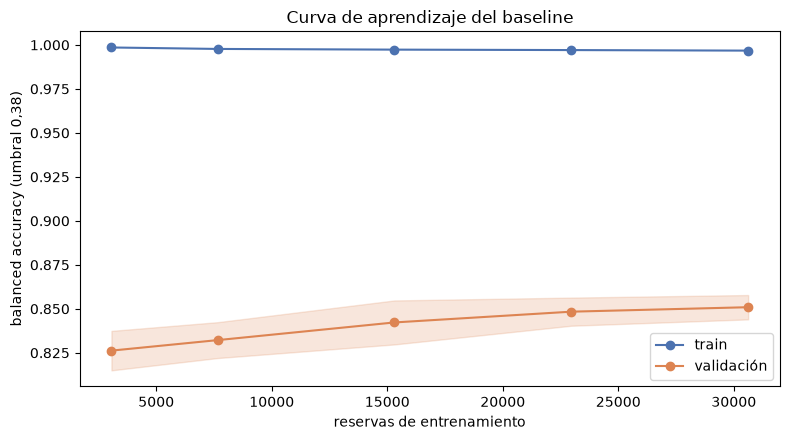

In [218]:
# CURVAS DE APRENDIZAJE DEL BASELINE

from sklearn.model_selection import learning_curve
from sklearn.metrics import balanced_accuracy_score

# Mismo modelo que el baseline: Random Forest con los hiperparámetros de la sección 6.4
modelo_curva = Pipeline([("preprocesar", preprocesador),
                         ("modelo", RandomForestClassifier(random_state=42, **mejores))])

# Balanced accuracy aplicando el umbral del baseline (sección 6.5) en lugar del 0,5 de predict
def ba_con_umbral(modelo, X, y):
    return balanced_accuracy_score(y, modelo.predict_proba(X)[:, 1] >= umbral_baseline)

# Proporción del train de cada fold que se usa para entrenar.
# La validación es siempre el fold completo, así todos los puntos se miden sobre los mismos datos.
proporciones = [0.1, 0.25, 0.5, 0.75, 1.0]

n_reservas, scores_train, scores_val = learning_curve(
    modelo_curva, X_train, y_train,
    train_sizes=proporciones, cv=cv, groups=grupos_train,
    scoring=ba_con_umbral, shuffle=True, random_state=42, n_jobs=-1,
)

curva_aprendizaje = pd.DataFrame({
    "proporcion": proporciones,
    "reservas_train": n_reservas,
    "BA_train": scores_train.mean(axis=1),
    "BA_validacion": scores_val.mean(axis=1),
    "desvio_validacion": scores_val.std(axis=1),
})
curva_aprendizaje["brecha"] = curva_aprendizaje["BA_train"] - curva_aprendizaje["BA_validacion"]
print(curva_aprendizaje.round(4).to_string(index=False))

# Cuánto mejora la validación en cada tramo
print("\nMejora en validación por tramo:")
for i in range(1, len(proporciones)):
    print(f"  {curva_aprendizaje['reservas_train'][i-1]:>6} -> {curva_aprendizaje['reservas_train'][i]:>6} reservas: "
          f"{curva_aprendizaje['BA_validacion'][i] - curva_aprendizaje['BA_validacion'][i-1]:+.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n_reservas, curva_aprendizaje["BA_train"], "o-", color="#4C72B0", label="train")
ax.plot(n_reservas, curva_aprendizaje["BA_validacion"], "o-", color="#DD8452", label="validación")
ax.fill_between(n_reservas,
                curva_aprendizaje["BA_validacion"] - curva_aprendizaje["desvio_validacion"],
                curva_aprendizaje["BA_validacion"] + curva_aprendizaje["desvio_validacion"],
                color="#DD8452", alpha=0.2)
ax.set_xlabel("reservas de entrenamiento")
ax.set_ylabel("balanced accuracy (umbral 0,38)")
ax.set_title("Curva de aprendizaje del baseline")
ax.legend()
plt.tight_layout()
plt.show()

Resultados:

- La validación mejora de forma sostenida al agregar datos, de 0,8254 con 3.062 reservas a 0,8504 con 30.621. Pero cada tramo aporta menos: el último, de 23.000 a 30.600 reservas, suma solo 0,003.
- El train queda cerca de 0,99 en todos los tamaños. El modelo tiene capacidad de sobra para ajustar los datos, así que no está limitado por ser demasiado simple.
- La brecha entre train y validación se achica a medida que crecen los datos, de 0,171 a 0,139, pero sigue siendo grande. Como se explicó en la sección 6.4, en un Random Forest esa brecha es esperable y no indica sobreajuste.

El valor con el 100% de los datos (0,8504) difiere levemente del 0,8517 de la sección 6.5 porque acá las reservas se mezclan antes de entrenar, y eso cambia la muestra con la que se arma cada árbol. La diferencia está dentro del desvío entre folds.

#### ¿Limitado por el modelo o por los datos?

El patrón corresponde a un sistema limitado por los datos más que por el modelo: la capacidad del modelo sobra y la validación todavía sube con más reservas. Sin embargo, la curva ya se está aplanando. Cada vez que se duplica la cantidad de datos, la balanced accuracy sube entre 0,007 y 0,01, así que duplicar el dataset completo aportaría una mejora de ese orden, no un salto grande.

#### ¿Más datos mejorarían significativamente el rendimiento?

Más reservas del mismo tipo darían una mejora moderada. El análisis de errores de la sección 7 sugiere que el límite principal no es la cantidad sino la información disponible: los falsos negativos tienen un perfil casi igual al de las reservas que no se cancelan, y con más ejemplos de ese mismo perfil el modelo seguiría sin poder distinguirlos. Por eso, más que sumar filas, lo que más puede mejorar el sistema es sumar variables nuevas que separen esos casos, como se propone en la adquisición de datos.

## 9. Estrategia data-centered

El análisis de errores de la sección 7 identificó a `cloud_marketplace` como la región donde más falla el modelo. En esta sección se justifica por qué es la cohorte prioritaria, se analizan las posibles causas de su mal rendimiento y se proponen los siguientes pasos para mejorarlo.

### 9.1 Cohorte prioritaria: `cloud_marketplace`

Para justificar la prioridad se consideran dos aspectos: la frecuencia del problema (qué tan seguido se equivoca el modelo en esta cohorte) y su impacto operativo (qué consecuencias tienen esos errores para la plataforma).

In [219]:
# FRECUENCIA E IMPACTO DEL PROBLEMA EN cloud_marketplace

es_cloud = analisis["client_type"] == "cloud_marketplace"
horas_gpu = analisis["peak_gpu_hours"] + analisis["offpeak_gpu_hours"]


def resumen_errores(grupo):
    """Rendimiento del modelo dentro de un grupo de reservas."""
    r = grupo["resultado"].value_counts()
    vp, vn, fp, fn = (r.get(t, 0) for t in ["VP", "VN", "FP", "FN"])
    recall_canceladas = vp / (vp + fn)
    recall_no_canceladas = vn / (vn + fp)
    return pd.Series({
        "reservas": len(grupo),
        "porc_train": len(grupo) / len(analisis) * 100,
        "tasa_cancelacion": grupo["real"].mean() * 100,
        "tasa_error": (fp + fn) / len(grupo) * 100,
        "BA": (recall_canceladas + recall_no_canceladas) / 2,
        "recall_canceladas": recall_canceladas,
        "recall_no_canceladas": recall_no_canceladas,
        "FN": fn,
        "FP": fp,
    })


comparacion_cloud = pd.DataFrame({
    "cloud_marketplace": resumen_errores(analisis[es_cloud]),
    "resto": resumen_errores(analisis[~es_cloud]),
}).T

print(comparacion_cloud.round(3).to_string())

# Impacto operativo: horas de GPU involucradas en cada tipo de error
print("\nHoras de GPU involucradas en los errores:")
for tipo in ["FN", "FP"]:
    es_tipo = analisis["resultado"] == tipo
    total = horas_gpu[es_tipo].sum()
    en_cloud = horas_gpu[es_tipo & es_cloud].sum()
    print(f"  {tipo}: {total:,.0f} horas en total, {en_cloud / total * 100:.1f}% en cloud_marketplace")

horas_canceladas = horas_gpu[analisis["real"] == 1].sum()
horas_no_detectadas = horas_gpu[analisis["resultado"] == "FN"].sum()
print(f"\nHoras de GPU de reservas canceladas que el modelo no detecta: "
      f"{horas_no_detectadas / horas_canceladas * 100:.1f}% del total de horas canceladas")

                   reservas  porc_train  tasa_cancelacion  tasa_error     BA  recall_canceladas  recall_no_canceladas      FN      FP
cloud_marketplace   18521.0      48.391            37.622      21.759  0.775              0.744                 0.805  1781.0  2249.0
resto               19753.0      51.609            45.548       7.827  0.920              0.898                 0.942   922.0   624.0

Horas de GPU involucradas en los errores:
  FN: 62,792 horas en total, 70.1% en cloud_marketplace
  FP: 75,896 horas en total, 83.0% en cloud_marketplace

Horas de GPU de reservas canceladas que el modelo no detecta: 16.1% del total de horas canceladas


**Frecuencia:** `cloud_marketplace` es el 48,4% del train, y el modelo se equivoca en el 21,8% de sus reservas, casi el triple que en el resto (7,8%). Su balanced accuracy es 0,775, frente a 0,920 en las demás cohortes. El problema aparece en las dos clases: el modelo detecta el 74,4% de sus cancelaciones y reconoce el 80,5% de sus reservas no canceladas.

**Impacto operativo:** Cada tipo de error tiene una consecuencia distinta para la plataforma:

- **Falsos negativos**: son cancelaciones que el modelo no anticipa. La plataforma mantiene reservadas GPUs que finalmente no se usan, en lugar de ofrecerlas a otros clientes. El 70,1% de las horas de GPU de estas reservas corresponde a `cloud_marketplace`.
- **Falsos positivos**: son reservas que el modelo da por canceladas pero que se ejecutan. Si la plataforma reasigna esos recursos confiando en la predicción, el cliente se queda sin la GPU que reservó, un error más grave para la relación con el cliente. El 83,0% de las horas de GPU de estas reservas corresponde a `cloud_marketplace`.

En total, el modelo no detecta el 16,1% de las horas de GPU canceladas, y la mayor parte se concentra en esta cohorte. Por frecuencia y por impacto, `cloud_marketplace` es la cohorte prioritaria: mejorar el rendimiento en este grupo es la vía con más margen para mejorar el sistema completo.

### 9.2 Posibles causas

Para entender por qué el modelo falla más en `cloud_marketplace`, se compara qué señales de cancelación tiene esta cohorte frente al resto. En la sección 7.4 se vio que el modelo acierta cuando las reservas tienen señales fuertes, como `locked_allocation` o cancelaciones previas.

In [220]:
# ¿POR QUÉ FALLA MÁS EN cloud_marketplace? SEÑALES DISPONIBLES EN CADA GRUPO

cloud = analisis[es_cloud]
resto = analisis[~es_cloud]


def porcentajes(grupo):
    return pd.Series({
        "locked_allocation": (grupo["reservation_commitment"] == "locked_allocation").mean() * 100,
        "con_cancelaciones_previas": (grupo["previous_job_cancellations"] > 0).mean() * 100,
        "sin_historial_en_la_plataforma": ((grupo["previous_job_cancellations"] == 0)
                                           & (grupo["successful_previous_jobs"] == 0)).mean() * 100,
        "cliente_que_vuelve": (grupo["returning_client"] == 1).mean() * 100,
        "por_broker_platform": (grupo["request_channel"] == "broker_platform").mean() * 100,
        "por_agente_9": (grupo["orchestration_agent_id"] == 9).mean() * 100,
        "probabilidad_entre_0,3_y_0,7": grupo["proba"].between(0.3, 0.7).mean() * 100,
    })


senales = pd.DataFrame({"cloud_marketplace": porcentajes(cloud), "resto": porcentajes(resto)})
print("Porcentaje de reservas de cada grupo:")
print(senales.round(1).to_string())

Porcentaje de reservas de cada grupo:
                                cloud_marketplace  resto
locked_allocation                             0.0   31.7
con_cancelaciones_previas                     1.2   12.1
sin_historial_en_la_plataforma               98.6   85.4
cliente_que_vuelve                            0.6    4.3
por_broker_platform                          99.4   75.2
por_agente_9                                 82.4    0.0
probabilidad_entre_0,3_y_0,7                 33.4   10.7


La comparación muestra que `cloud_marketplace` carece casi por completo de las señales que el modelo usa para detectar cancelaciones:

- **Sin compromiso contractual fuerte**: ninguna reserva de `cloud_marketplace` tiene `locked_allocation`, la variable más predictiva del dataset, frente al 31,7% del resto.
- **Sin historial del cliente**: el 98,6% de sus reservas viene de clientes sin reservas previas en la plataforma, ni canceladas ni completadas. Solo el 1,2% tiene cancelaciones previas (12,1% en el resto) y apenas el 0,6% son clientes que vuelven (4,3% en el resto).
- **Reservas mediadas**: el 99,4% se hace por `broker_platform` y el 82,4% pasa por el agente 9. La plataforma solo ve lo que el intermediario le transmite de la reserva, no al cliente final.

Como consecuencia, el modelo está mucho menos seguro en esta cohorte: el 33,4% de sus reservas recibe una probabilidad entre 0,3 y 0,7, frente al 10,7% en el resto. No se trata de que el modelo aprenda mal, sino de que estas reservas llegan con mucha menos información.

Antes de proponer estrategias, se descarta una solución simple: usar un umbral de decisión propio para esta cohorte. También se mira si el error se concentra en algún agente en particular.

In [221]:
# ¿ALCANZA CON UN UMBRAL PROPIO PARA cloud_marketplace?

umbrales_prueba = np.round(np.arange(0.20, 0.71, 0.01), 2)
ba_cloud = [balanced_accuracy_score(cloud["real"], cloud["proba"] >= u) for u in umbrales_prueba]
mejor_umbral_cloud = umbrales_prueba[int(np.argmax(ba_cloud))]

print(f"BA de cloud_marketplace con el umbral del baseline ({umbral:.2f}): "
      f"{balanced_accuracy_score(cloud['real'], cloud['proba'] >= umbral):.4f}")
print(f"BA de cloud_marketplace con su mejor umbral ({mejor_umbral_cloud:.2f}): {max(ba_cloud):.4f}")

# Dentro de cloud_marketplace, ¿el error se concentra en algún agente?
por_agente = cloud.groupby(cloud["orchestration_agent_id"].fillna(-1).astype(int)).agg(
    reservas=("resultado", "size"),
    tasa_cancelacion=("real", "mean"),
    tasa_error=("resultado", lambda r: r.isin(["FP", "FN"]).mean()),
).sort_values("reservas", ascending=False)

print("\nAgentes con más reservas dentro de cloud_marketplace:")
print(por_agente.head(5).round(3).to_string())

BA de cloud_marketplace con el umbral del baseline (0.43): 0.7749
BA de cloud_marketplace con su mejor umbral (0.38): 0.7774

Agentes con más reservas dentro de cloud_marketplace:
                        reservas  tasa_cancelacion  tasa_error
orchestration_agent_id                                        
9                          15264             0.419       0.246
7                           1705             0.130       0.068
8                            572             0.311       0.107
83                           154             0.364       0.143
11                           146             0.103       0.068


Un umbral propio para `cloud_marketplace` prácticamente no cambia el resultado: la balanced accuracy pasa de 0,7749 a 0,7774. El problema no es dónde se corta la probabilidad, sino que el modelo no tiene información suficiente para separar bien las dos clases dentro de esta cohorte.

Además, el error se concentra en el agente 9, que canaliza 15.264 reservas de la cohorte con una tasa de error del 24,6%. Los otros agentes de `cloud_marketplace` tienen tasas de error mucho más bajas (entre 7% y 14%). Por lo tanto, la región más problemática es más específica que la cohorte completa: son las reservas de clientes sin historial que llegan a través del agente 9.

Un umbral propio para `cloud_marketplace` prácticamente no cambia el resultado: la balanced accuracy pasa de 0,7749 a 0,7774. El problema no es dónde se corta la probabilidad, sino que el modelo no tiene información suficiente para separar bien las dos clases dentro de esta cohorte.

Además, el error se concentra en el agente 9, que canaliza 15.264 reservas de la cohorte con una tasa de error del 24,6%. Los otros agentes de `cloud_marketplace` tienen tasas de error mucho más bajas (entre 7% y 14%). Por lo tanto, la región más problemática es más específica que la cohorte completa: son las reservas de clientes sin historial que llegan a través del agente 9.

### 9.3 Siguientes pasos y estrategias de mejora

#### Estrategias para `cloud_marketplace`

Se proponen tres estrategias, ordenadas de menor a mayor costo de implementación:

- **Crear variables a partir de la información de la reserva**: como estas reservas no tienen historial del cliente, hay que aprovechar mejor lo que sí trae la propia reserva. Por ejemplo, el precio relativo (cuánto más caro o más barato es el costo por hora frente al de otras reservas con la misma fecha y tipo de GPU), la duración total de la reserva o la combinación entre la anticipación y el agente.
- **Modelos o pesos específicos para la cohorte**: como el comportamiento de `cloud_marketplace` difiere tanto del resto, se puede evaluar un modelo entrenado solo con esta cohorte, o darle más peso durante el entrenamiento. El ajuste de umbral por cohorte ya se descartó porque casi no mejora el resultado.
- **Incorporar información nueva**: el límite principal es la falta de información sobre el cliente final, que hoy queda oculto detrás del intermediario. Las secciones 7.4 y 9.2 muestran que el modelo no puede distinguir estas reservas con las variables actuales. Qué datos conviene incorporar se desarrolla en la siguiente sección.

#### Otras áreas de mejora

El análisis de errores también señaló otras regiones y aspectos del sistema donde hay margen para mejorar:

- **Tipos de cliente que casi no cancelan**: en `independent_client`, `sponsored_project` y `high_priority_partner`, el modelo detecta muy pocas cancelaciones porque son eventos raros dentro de cada grupo. Pesan poco en el total de errores, pero se podrían mejorar con estrategias para clases desbalanceadas, como dar más peso a las cancelaciones de estos grupos durante el entrenamiento.
- **Falsos positivos cerca del umbral**: una parte importante de los falsos positivos tiene probabilidades cercanas al umbral. Un modelo que estime mejor las probabilidades podría resolver estos casos dudosos. Es el caso de los modelos de boosting, que según la clase 12 suelen rendir mejor que el Random Forest en datos tabulares.
- **Calidad de los datos**: en la sección 3.2 se detectó que el 40,6% de las reservas tiene al menos una copia idéntica. Se podría revisar si los grupos de copias con resultados distintos (algunas canceladas y otras no) son reservas reales en bloque o inconsistencias de registro, y si conviene tratarlos de otra forma.

#### Cómo se evaluarán

Cada estrategia se evaluará en la etapa de optimización con el mismo esquema de validación cruzada, comparando contra el baseline. Además de la balanced accuracy global se medirá la de `cloud_marketplace`, para saber si cada mejora es global o específica de esta cohorte.

## 10. Adquisición de datos

El análisis de errores (sección 7) mostró que la mayoría de los falsos negativos no tiene ninguna de las señales que en este dataset anticipan una cancelación: no tienen `locked_allocation` ni cancelaciones previas, se reservan con poca anticipación y suelen tener pedidos especiales. Con las variables actuales son indistinguibles de las reservas que sí se ejecutan. A su vez, la curva de aprendizaje (sección 8) mostró que sumar más reservas del mismo tipo mejoraría poco el rendimiento. Por eso, lo que más puede mejorar el sistema no es conseguir más filas, sino variables nuevas que capten si el cliente realmente piensa usar la reserva.

Se proponen los siguientes datos, en orden de prioridad:

1. **Compromiso económico de la reserva**: si se pagó por adelantado, si hay depósito y cuál es la penalidad por cancelar. `reservation_commitment` es la señal más fuerte del dataset, pero solo distingue unas pocas categorías. Saber cuánto pierde el cliente si cancela permitiría separar mejor las reservas sin compromiso fuerte, que es donde están los falsos negativos. Se obtiene del sistema de facturación. En `cloud_marketplace` esto es aún más relevante: ninguna de sus reservas tiene `locked_allocation`, así que hoy el modelo no tiene ninguna señal de compromiso económico para esta cohorte.
2. **Actividad del cliente entre la reserva y la ejecución**: si confirmó la reserva, si subió el código o los datos del workload, si entró a la plataforma o hizo consultas al soporte. Es la información que mejor refleja si el cliente sigue planeando usar los recursos, y es especialmente útil en las reservas con poca anticipación, donde hoy el modelo no tiene pistas. Se obtiene de los registros de la plataforma.
3. **Contexto de mercado para `cloud_marketplace`**: el precio de recursos equivalentes en otros proveedores y si el cliente tiene reservas similares en paralelo. En un marketplace es común reservar en más de un lugar y cancelar las que sobran, o cancelar si aparece una oferta mejor. Esta cohorte concentra el 72% de los errores y el 65,9% de los falsos negativos, así que es donde estos datos tendrían más impacto.
4. **Historial más completo del cliente**: antigüedad de la cuenta y comportamiento en reservas anteriores, no solo la cantidad de cancelaciones previas. Casi ningún falso negativo tiene cancelaciones previas registradas, y en `cloud_marketplace` el 98,6% de las reservas viene de clientes sin ningún historial en la plataforma. Como estos clientes reservan a través de un intermediario, una opción es obtener su historial desde el propio marketplace, que sí los conoce.

Todos estos datos tienen que estar disponibles en el momento de hacer la predicción. Por ejemplo, la actividad del cliente debe medirse solo hasta ese momento. Si se incluyera lo que pasa después, se repetiría el problema de leakage de `execution_status`.

Para validar la propuesta, se podría incorporar primero el dato más fácil de conseguir y comparar el rendimiento antes y después, mirando en particular la cohorte `cloud_marketplace` y los falsos negativos.